# COSMOS1–4: Number of successfully measured 7DT bands

FINALCAT의 각 천체를 기존 `finalcat_idx`로 COSMOS1–4 마스터 카탈로그에 연결하고, 중복 천체는 한 번만 집계합니다. 2.2와 동일하게 전역변수와 카탈로그 로딩으로 시작합니다.

- **측광 성공**: 밴드의 `source_id >= 0`, 유한한 `0 < mag < 50`, 유한한 `mag_err > 0`. 추가 S/N 제한은 적용하지 않습니다.
- **중복 선택**: 7DT 매칭 여부 → 성공 밴드 수(많은 순) → 성공 밴드의 중앙 등급 오차(작은 순) → FINALCAT 매칭 거리(작은 순) → 필드 번호. 한 천체에는 한 필드의 데이터만 사용합니다.
- **r magnitude**: FINALCAT의 `RM` [AB]. `m600`이나 SDSS r로 대체하지 않습니다.
- 전체 밴드 수는 **20개**입니다. 필드별 미관측 밴드는 성공으로 세지 않습니다. `not-all`은 매칭된 천체 중 성공 밴드가 20개 미만인 경우이며, 관측 가능한 밴드만 모두 성공했는지도 별도로 저장합니다.
- 커버리지는 2.2처럼 기존 마스터 카탈로그에 FINALCAT 행이 있는지로 판정합니다. 커버리지 밖의 천체를 0밴드 표본에 섞지 않습니다.

## Global variables and master catalogs

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table, vstack
from astropy.visualization import ImageNormalize, ZScaleInterval
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'Notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
FIELDS = (1, 2, 3, 4)
BANDS_7DT = tuple(f'm{i}' for i in range(400, 900, 25))
N_TOTAL_BANDS = len(BANDS_7DT)
MIN_SUCCESS_BANDS = 15
RANDOM_SEED = 20261015
N_EXAMPLES = 5
PIXEL_RANGE = 40
DATA_ROOT = PROJECT_ROOT / 'COSMOS_data'
ANALYSIS_DIR = PROJECT_ROOT / 'output/singlephot/analysis/numofmatchedbands'
EXAMPLE_DIR = ANALYSIS_DIR / 'examples'
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)
FINALCAT_PATH = DATA_ROOT / 'COSMOS_finalcat.fits'
MASTER_PATHS = {field: PROJECT_ROOT / f'output/COSMOS{field}/singlephot/master_catalog.fits' for field in FIELDS}
finalcat = Table.read(FINALCAT_PATH)
masters = {field: Table.read(path) for field, path in MASTER_PATHS.items()}

def get_image_path(cosmos, band):
    paths = sorted((DATA_ROOT / f'COSMOS{cosmos}').glob(f'*{band}*.com.fits'))
    if len(paths) != 1:
        raise FileNotFoundError(f'Expected one COSMOS{cosmos} {band} image; found {len(paths)}')
    return paths[0]

def get_weight_path(cosmos, band):
    paths = sorted((DATA_ROOT / f'COSMOS{cosmos}').glob(f'*{band}*.weight.fits'))
    if len(paths) != 1:
        raise FileNotFoundError(f'Expected one COSMOS{cosmos} {band} weight image; found {len(paths)}')
    return paths[0]

active_by_field = {}
for field in FIELDS:
    active = []
    for band in BANDS_7DT:
        try:
            get_image_path(field, band)
            get_weight_path(field, band)
        except FileNotFoundError:
            continue
        active.append(band)
    active_by_field[field] = tuple(active)
    if not active:
        raise RuntimeError(f'COSMOS{field}: no available bands')
    print(f'COSMOS{field}: {len(masters[field]):,} master rows; {len(active)} active bands; missing: {sorted(set(BANDS_7DT) - set(active))}')
print(f'FINALCAT: {len(finalcat):,} sources; output: {ANALYSIS_DIR}')

COSMOS1: 88,361 master rows; 20 active bands; missing: []
COSMOS2: 93,083 master rows; 16 active bands; missing: ['m650', 'm675', 'm800', 'm825']
COSMOS3: 82,144 master rows; 18 active bands; missing: ['m650', 'm675']
COSMOS4: 88,378 master rows; 16 active bands; missing: ['m450', 'm475', 'm650', 'm675']
FINALCAT: 126,280 sources; output: /Users/mac_seo/Research_local/7DTonCOSMOS/output/singlephot/analysis/numofmatchedbands


## Resolve overlaps and build one row per FINALCAT source

각 후보의 원본 필드, 마스터 행, 성공/검출 밴드 수와 선택 여부를 저장합니다. 필드 간 밴드 합집합을 만들지 않으므로 같은 천체를 여러 번 세거나 서로 다른 관측의 측광을 혼합하지 않습니다.

In [2]:
def numeric(table, name, default=np.nan):
    return np.asarray(np.ma.filled(table[name], default), dtype=float)

def successful_photometry(table, active_bands):
    success = np.zeros((len(table), N_TOTAL_BANDS), dtype=bool)
    detected = np.zeros_like(success)
    errors = np.full(success.shape, np.nan)
    for j, band in enumerate(BANDS_7DT):
        sid = numeric(table, f'{band}_source_id', -1)
        detected[:, j] = sid >= 0
        mag = numeric(table, f'{band}_mag')
        err = numeric(table, f'{band}_mag_err')
        success[:, j] = detected[:, j] & np.isfinite(mag) & (mag > 0) & (mag < 50) & np.isfinite(err) & (err > 0)
        if band not in active_bands:
            assert not detected[:, j].any(), f'{band}: catalog detections exist but image/weight files are missing'
            success[:, j] = False
        errors[success[:, j], j] = err[success[:, j]]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        median_error = np.nanmedian(errors, axis=1)
    return success, detected, median_error

candidate_tables = []
success_by_field = {}
n_coverage = np.zeros(len(finalcat), dtype=np.int16)
n_matched_fields = np.zeros(len(finalcat), dtype=np.int16)
for field, master in masters.items():
    idx = numeric(master, 'finalcat_idx', -1).astype(np.int64)
    linked = np.flatnonzero(idx >= 0)
    fid = idx[linked]
    assert (fid < len(finalcat)).all()
    assert len(np.unique(fid)) == len(fid), f'COSMOS{field}: duplicate finalcat_idx'
    assert np.array_equal(np.asarray(master['finalcat_ID'][linked]).astype(str), np.asarray(finalcat['ID'][fid]).astype(str))
    success, detected, median_error = successful_photometry(master, active_by_field[field])
    success_by_field[field] = success
    assert np.array_equal(detected.sum(axis=1), numeric(master, 'n_7dt_bands', 0).astype(int))
    matched = np.asarray(master['has_7dt'], dtype=bool)[linked]
    assert np.array_equal(matched, np.asarray(master['master_class'][linked]).astype(str) == 'matched')
    n_coverage[fid] += 1
    n_matched_fields[fid] += matched.astype(np.int16)
    candidate = Table()
    candidate['finalcat_idx'] = fid
    candidate['COSMOS'] = np.full(len(fid), field, dtype=np.int16)
    candidate['master_row'] = linked
    candidate['master_id'] = master['master_id'][linked]
    candidate['has_7dt'] = matched
    candidate['n_success'] = success.sum(axis=1)[linked].astype(np.int16)
    candidate['n_detected'] = detected.sum(axis=1)[linked].astype(np.int16)
    candidate['n_available'] = np.full(len(fid), len(active_by_field[field]), dtype=np.int16)
    candidate['median_mag_err'] = median_error[linked]
    candidate['sep_arcsec'] = numeric(master, 'finalcat_sep_arcsec')[linked]
    candidate_tables.append(candidate)

candidates = vstack(candidate_tables)
# np.lexsort: last key is primary. Group by FINALCAT, then rank candidates.
order = np.lexsort((np.asarray(candidates['COSMOS']),
                    np.nan_to_num(candidates['sep_arcsec'], nan=np.inf),
                    np.nan_to_num(candidates['median_mag_err'], nan=np.inf),
                    -np.asarray(candidates['n_success']),
                    -np.asarray(candidates['has_7dt'], dtype=int),
                    np.asarray(candidates['finalcat_idx'])))
sorted_idx = np.asarray(candidates['finalcat_idx'])[order]
first = np.r_[True, np.diff(sorted_idx) != 0]
chosen_indices = order[first]
chosen = candidates[chosen_indices]
candidates['selected'] = np.zeros(len(candidates), dtype=bool)
candidates['selected'][chosen_indices] = True

combined = finalcat[['ID', 'RA', 'DEC', 'RM', 'RMERR']].copy()
combined['finalcat_idx'] = np.arange(len(finalcat), dtype=np.int64)
combined['n_COSMOS_coverage'] = n_coverage
combined['n_COSMOS_7dt_matches'] = n_matched_fields
combined['in_coverage'] = n_coverage > 0
combined['has_7dt_any'] = n_matched_fields > 0
for name, src, fill, dtype in [
    ('selected_COSMOS', 'COSMOS', 0, np.int16),
    ('selected_master_row', 'master_row', -1, np.int64),
    ('selected_master_id', 'master_id', -1, np.int64),
    ('n_success_bands', 'n_success', 0, np.int16),
    ('n_detected_bands', 'n_detected', 0, np.int16),
    ('n_available_bands', 'n_available', 0, np.int16),
    ('median_mag_err', 'median_mag_err', np.nan, float),
    ('finalcat_sep_arcsec', 'sep_arcsec', np.nan, float),
]:
    values = np.full(len(finalcat), fill, dtype=dtype)
    values[np.asarray(chosen['finalcat_idx'])] = chosen[src]
    combined[name] = values
for j, band in enumerate(BANDS_7DT):
    success = np.zeros(len(finalcat), dtype=bool)
    for field in FIELDS:
        subset = chosen[np.asarray(chosen['COSMOS']) == field]
        success[np.asarray(subset['finalcat_idx'])] = success_by_field[field][np.asarray(subset['master_row']), j]
    combined[f'{band}_success'] = success
    for suffix in ('source_id', 'mag', 'mag_err'):
        values = np.full(len(finalcat), -1 if suffix == 'source_id' else np.nan,
                         dtype=np.int64 if suffix == 'source_id' else float)
        for field in FIELDS:
            subset = chosen[np.asarray(chosen['COSMOS']) == field]
            values[np.asarray(subset['finalcat_idx'])] = numeric(masters[field], f'{band}_{suffix}', -1 if suffix == 'source_id' else np.nan)[np.asarray(subset['master_row'])]
        combined[f'{band}_{suffix}'] = values
combined['all_20_success'] = np.asarray(combined['n_success_bands']) == N_TOTAL_BANDS
combined['all_available_success'] = combined['in_coverage'] & (combined['n_success_bands'] == combined['n_available_bands'])
matched_mask = np.asarray(combined['has_7dt_any'], dtype=bool)
matched_catalog = combined[matched_mask]
ge15_mask = matched_mask & (np.asarray(combined['n_success_bands']) >= MIN_SUCCESS_BANDS)
not_all_mask = matched_mask & ~np.asarray(combined['all_20_success'])
assert len(np.unique(chosen['finalcat_idx'])) == int((n_coverage > 0).sum())
assert np.array_equal(np.asarray(chosen['has_7dt']), matched_mask[np.asarray(chosen['finalcat_idx'])])
assert np.array_equal(sum(np.asarray(combined[f'{b}_success'], dtype=int) for b in BANDS_7DT), np.asarray(combined['n_success_bands']))
# Verify each selected row has the maximum success-band count across its fields.
max_success = np.zeros(len(finalcat), dtype=int)
np.maximum.at(max_success, np.asarray(candidates['finalcat_idx']), np.asarray(candidates['n_success']))
assert np.array_equal(max_success, np.asarray(combined['n_success_bands']))
combined.write(ANALYSIS_DIR / 'cosmos1-4_finalcat_band_success_catalog.fits', overwrite=True)
candidates.write(ANALYSIS_DIR / 'cosmos1-4_field_selection_candidates.fits', overwrite=True)
summary = {
    'n_finalcat': len(finalcat), 'n_in_coverage': int((n_coverage > 0).sum()),
    'n_outside_coverage': int((n_coverage == 0).sum()),
    'n_unique_matched': int(matched_mask.sum()),
    'n_matched_in_multiple_fields': int((n_matched_fields > 1).sum()),
    'n_ge15_success': int(ge15_mask.sum()),
    'n_all20_success': int(np.asarray(combined['all_20_success']).sum()),
    'n_matched_not_all20': int(not_all_mask.sum()),
    'n_matched_all_available_success': int(np.asarray(combined['all_available_success'])[matched_mask].sum()),
    'random_seed': RANDOM_SEED,
    'active_bands_by_field': {str(f): list(active_by_field[f]) for f in FIELDS},
}
(ANALYSIS_DIR / 'summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
display(matched_catalog[['ID', 'RM', 'selected_COSMOS', 'n_COSMOS_7dt_matches', 'n_success_bands', 'n_available_bands']][:10])

{
  "n_finalcat": 126280,
  "n_in_coverage": 126153,
  "n_outside_coverage": 127,
  "n_unique_matched": 9326,
  "n_matched_in_multiple_fields": 3175,
  "n_ge15_success": 809,
  "n_all20_success": 215,
  "n_matched_not_all20": 9111,
  "n_matched_all_available_success": 373,
  "random_seed": 20261015,
  "active_bands_by_field": {
    "1": [
      "m400",
      "m425",
      "m450",
      "m475",
      "m500",
      "m525",
      "m550",
      "m575",
      "m600",
      "m625",
      "m650",
      "m675",
      "m700",
      "m725",
      "m750",
      "m775",
      "m800",
      "m825",
      "m850",
      "m875"
    ],
    "2": [
      "m400",
      "m425",
      "m450",
      "m475",
      "m500",
      "m525",
      "m550",
      "m575",
      "m600",
      "m625",
      "m700",
      "m725",
      "m750",
      "m775",
      "m850",
      "m875"
    ],
    "3": [
      "m400",
      "m425",
      "m450",
      "m475",
      "m500",
      "m525",
      "m550",
      "m575",
      "m6

ID,RM,selected_COSMOS,n_COSMOS_7dt_matches,n_success_bands,n_available_bands
bytes20,float32,int16,int16,int16,int16
149.734135+02.691082,21.394363,2,1,1,16
149.743972+02.729159,20.275064,2,1,5,16
149.748416+02.724866,20.869638,2,1,4,16
149.701143+01.802744,20.418941,1,1,6,20
149.703558+01.801806,21.95463,1,1,1,20
149.698603+01.766917,23.676636,1,1,1,20
149.708719+01.771798,19.010408,1,1,8,20
149.710742+01.776964,20.820972,1,1,5,20
149.717017+01.814860,20.294004,1,1,3,20


## 1. Histogram of successful bands

주 표본은 중복 제거된 전체 FINALCAT–7DT 매칭 천체입니다. 커버리지 내 미검출 FINALCAT 천체는 회색 선의 0밴드에 별도 포함합니다. 커버리지 밖 천체는 제외합니다.

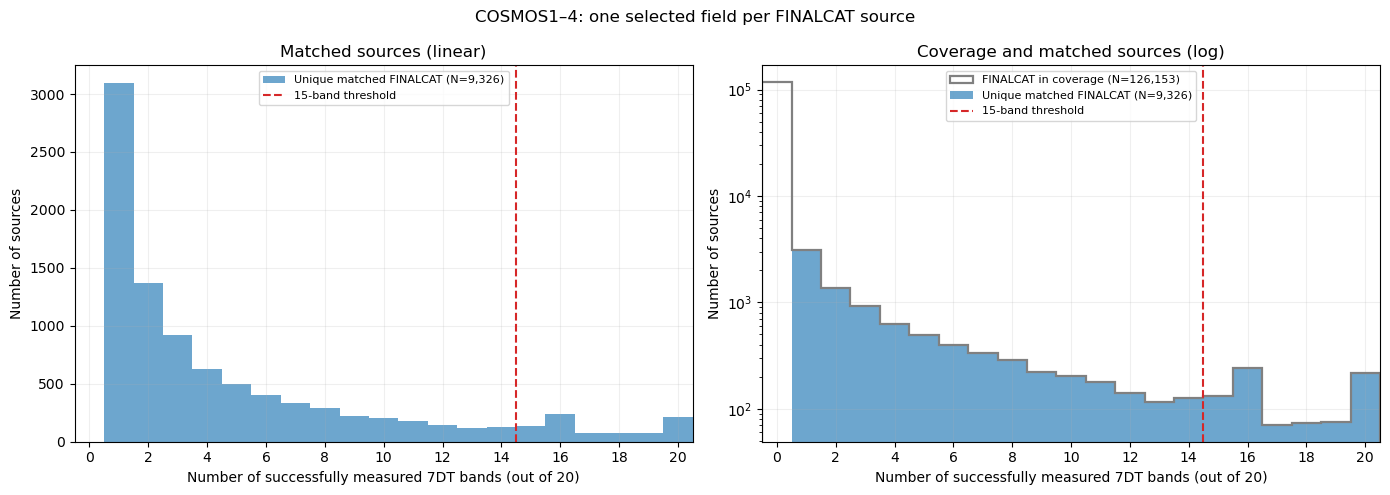

n_success_bands,n_matched_finalcat,n_finalcat_in_coverage
int64,int64,int64
0,0,116827
1,3093,3093
2,1369,1369
3,919,919
4,631,631
5,495,495
6,400,400
7,331,331
8,287,287


In [3]:
band_bins = np.arange(-0.5, N_TOTAL_BANDS + 1.5, 1)
n_success = np.asarray(combined['n_success_bands'])
counts_matched, _ = np.histogram(n_success[matched_mask], bins=band_bins)
counts_covered, _ = np.histogram(n_success[n_coverage > 0], bins=band_bins)
hist_table = Table([np.arange(N_TOTAL_BANDS + 1), counts_matched, counts_covered],
                   names=['n_success_bands', 'n_matched_finalcat', 'n_finalcat_in_coverage'])
hist_table.write(ANALYSIS_DIR / 'band_count_histogram.csv', format='ascii.csv', overwrite=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, log in zip(axes, (False, True)):
    if log:
        ax.hist(n_success[n_coverage > 0], bins=band_bins, histtype='step', color='gray', linewidth=1.6,
                label=f'FINALCAT in coverage (N={int((n_coverage > 0).sum()):,})')
    ax.hist(n_success[matched_mask], bins=band_bins, color='tab:blue', alpha=0.65,
            label=f'Unique matched FINALCAT (N={int(matched_mask.sum()):,})')
    ax.axvline(MIN_SUCCESS_BANDS - 0.5, color='tab:red', linestyle='--', label='15-band threshold')
    ax.set(xlabel='Number of successfully measured 7DT bands (out of 20)', ylabel='Number of sources',
           xticks=np.arange(0, 21, 2), xlim=(-0.5, 20.5), title='Coverage and matched sources (log)' if log else 'Matched sources (linear)')
    if log: ax.set_yscale('log')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle('COSMOS1–4: one selected field per FINALCAT source')
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / 'successful_band_count_histogram.png', dpi=160, bbox_inches='tight')
plt.show()
display(hist_table)

## 2. r magnitude: ≥15 successful bands versus all matched sources

두 히스토그램 모두 중복 제거와 동일한 유효 RM 조건을 사용하며, 공통 bin에서 천체 수를 비교합니다. 아래 패널은 해당 등급 구간의 ≥15밴드 비율입니다.

Matched sources without valid RM: 583
>=15-band sources without valid RM: 406


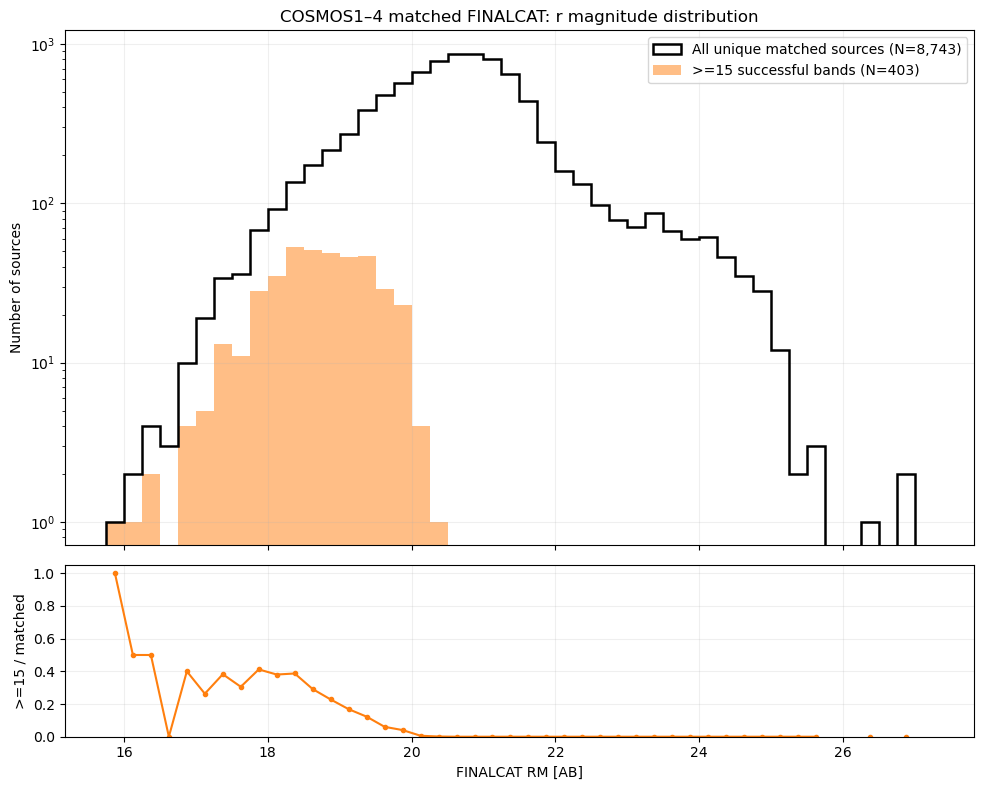

In [4]:
rm = numeric(combined, 'RM')
valid_rm = np.isfinite(rm) & (rm > 0) & (rm < 50)
all_rm_mask = matched_mask & valid_rm
subset_rm_mask = ge15_mask & valid_rm
print(f'Matched sources without valid RM: {int((matched_mask & ~valid_rm).sum())}')
print(f'>=15-band sources without valid RM: {int((ge15_mask & ~valid_rm).sum())}')
if not all_rm_mask.any():
    raise RuntimeError('No valid FINALCAT RM values in matched catalog')
mag_bins = np.arange(np.floor(rm[all_rm_mask].min() * 4) / 4,
                     np.ceil(rm[all_rm_mask].max() * 4) / 4 + 0.5, 0.25)
all_counts, _ = np.histogram(rm[all_rm_mask], bins=mag_bins)
subset_counts, _ = np.histogram(rm[subset_rm_mask], bins=mag_bins)
assert all_counts.sum() == int(all_rm_mask.sum())
assert subset_counts.sum() == int(subset_rm_mask.sum())
assert (subset_counts <= all_counts).all()
fraction = np.divide(subset_counts, all_counts, out=np.full(len(all_counts), np.nan), where=all_counts > 0)
mag_hist = Table([mag_bins[:-1], mag_bins[1:], all_counts, subset_counts, fraction],
                 names=['rm_lo', 'rm_hi', 'n_all_matched', 'n_ge15_bands', 'fraction_ge15'])
mag_hist.write(ANALYSIS_DIR / 'rm_histogram_ge15_vs_all_matched.csv', format='ascii.csv', overwrite=True)
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
axes[0].hist(rm[all_rm_mask], bins=mag_bins, histtype='step', color='black', linewidth=1.8,
             label=f'All unique matched sources (N={int(all_rm_mask.sum()):,})')
axes[0].hist(rm[subset_rm_mask], bins=mag_bins, color='tab:orange', alpha=0.5,
             label=f'>=15 successful bands (N={int(subset_rm_mask.sum()):,})')
axes[0].set(yscale='log', ylabel='Number of sources', title='COSMOS1–4 matched FINALCAT: r magnitude distribution')
axes[0].legend()
axes[1].plot((mag_bins[:-1] + mag_bins[1:]) / 2, fraction, 'o-', color='tab:orange', markersize=3)
axes[1].set(xlabel='FINALCAT RM [AB]', ylabel='>=15 / matched', ylim=(0, 1.05))
for ax in axes: ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / 'rm_histogram_ge15_vs_all_matched.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Five random not-all-band examples

2.2의 `plot_SourceInfoFromCatalog`, `plot_SourceImgFromCatalog`와 S/N 보조 함수를 그대로 가져오되, 밴드 cutout은 항상 20개 슬롯을 사용하여 미관측 밴드를 표시합니다. 고정 seed로 중복 없이 5개를 추출하고 각 천체에 선택된 필드의 영상과 카탈로그를 사용합니다. 성공 밴드 표, 검출 영상, 밴드 cutout, 진단 플롯을 모두 저장합니다.

In [5]:
# Inspection methods copied from notebook 2.2; only unobserved-band display adapted.
class SourceInfoResult(dict):
    '''Dictionary result with a compact notebook representation.'''
    def __repr__(self):
        return f"SourceInfoResult(master_id={self['master_id']}, keys={list(self.keys())})"

    def _repr_pretty_(self, printer, cycle):
        printer.text(repr(self))

def plot_SourceInfoFromCatalog(
    cat, image=None, pixel_range=40, source_id=None, *,
    info_catalog=None, population_catalog=None, diagnostic_band='m600', show=True,
):
    '''Display source metadata, images, photometry, and population diagnostics.'''
    if len(cat) == 0:
        raise ValueError('The input catalog is empty.')
    required = {'master_id', 'master_x', 'master_y'}
    missing = required.difference(cat.colnames)
    if missing:
        raise KeyError(f'Catalog is missing required columns: {sorted(missing)}')
    if pixel_range is None or not np.isfinite(pixel_range) or pixel_range <= 0:
        raise ValueError('pixel_range must be a positive number.')
    info_catalog = cat if info_catalog is None else info_catalog
    population_catalog = cat if population_catalog is None else population_catalog
    info_ids = np.asarray(info_catalog['master_id'], dtype=np.int64)
    cat_ids = np.asarray(cat['master_id'], dtype=np.int64)
    if source_id is None:
        selected_id = int(cat_ids[np.random.default_rng().integers(len(cat))])
    else:
        selected_id = int(source_id)
    matches = np.flatnonzero(info_ids == selected_id)
    cat_matches = np.flatnonzero(cat_ids == selected_id)
    if len(matches) != 1:
        raise KeyError(f'master_id={selected_id} must occur exactly once in info_catalog; found {len(matches)}.')
    if len(cat_matches) != 1:
        raise KeyError(f'master_id={selected_id} must occur exactly once in cat; found {len(cat_matches)}.')
    row = info_catalog[int(matches[0])]
    image_row = cat[int(cat_matches[0])]

    def value(name, default=np.nan):
        if name not in row.colnames:
            return default
        raw = row[name]
        if np.ma.is_masked(raw):
            return default
        return raw.item() if hasattr(raw, 'item') else raw

    def number(name):
        try:
            return float(value(name))
        except (TypeError, ValueError):
            return np.nan

    def display_value(name):
        raw = value(name, np.ma.masked)
        if np.ma.is_masked(raw):
            return '--'
        if isinstance(raw, (bytes, np.bytes_, str)):
            text = raw.decode(errors='replace').strip() if isinstance(raw, (bytes, np.bytes_)) else str(raw).strip()
            return '--' if text in {'', 'NN', 'nan'} else text
        try:
            numeric = float(raw)
        except (TypeError, ValueError):
            return str(raw)
        if not np.isfinite(numeric) or numeric in {-9.0, -99.0, -999.0}:
            return '--'
        return str(int(raw)) if isinstance(raw, (int, np.integer)) else f'{numeric:.6g}'

    selected_x = float(image_row['master_x'])
    selected_y = float(image_row['master_y'])
    if not np.isfinite(selected_x) or not np.isfinite(selected_y):
        raise ValueError('The selected source has a non-finite pixel position in cat.')
    summary = Table()
    summary['master_id'] = [selected_id]
    summary['master_class'] = [str(value('master_class', ''))]
    summary['master_ra'] = [number('master_ra')]
    summary['master_dec'] = [number('master_dec')]
    summary['master_x'] = [selected_x]
    summary['master_y'] = [selected_y]
    summary['n_7dt_bands'] = [int(value('n_7dt_bands', 0))]
    summary['has_finalcat'] = [bool(value('has_finalcat', False))]
    summary['has_sdss'] = [bool(value('has_sdss', False))]
    print(f'\nSource information: master_id={selected_id}')
    print('Image/catalog position')
    summary.pprint(max_lines=-1, max_width=-1)
    print('\nDetection-image cutout')
    image_fig, image_ax, selected_id = plot_SourceImgFromCatalog(
        cat, image=image, pixel_range=pixel_range, source_id=selected_id, show=show
    )

    x = int(round(selected_x - 1))
    y = int(round(selected_y - 1))
    samples = []
    for band in ACTIVE_BANDS:
        flat = band_images[band].reshape(-1)
        step = max(1, len(flat) // 5000)
        sample = np.asarray(flat[::step][:5000], dtype=float)
        samples.append(sample[np.isfinite(sample)])
    pooled = np.concatenate(samples)
    if pooled.size == 0:
        raise ValueError('The 7DT images contain no finite pixels for ZScale.')
    vmin, vmax = ZScaleInterval(n_samples=len(pooled)).get_limits(pooled)
    band_norm = ImageNormalize(vmin=vmin, vmax=vmax)
    xs = np.ma.filled(cat['master_x'], np.nan).astype(float)
    ys = np.ma.filled(cat['master_y'], np.nan).astype(float)
    classes = np.asarray(cat['master_class']).astype(str) if 'master_class' in cat.colnames else np.full(len(cat), 'source')
    class_colors = {'matched': 'purple', '7dt_only': 'tab:red', 'finalcat_only': 'tab:blue'}
    band_fig, band_axes = plt.subplots(4, 5, figsize=(15, 11), sharex=False, sharey=False)
    for band, ax in zip(BANDS_7DT, band_axes.flat):
        if band not in ACTIVE_BANDS:
            ax.set_title(f'{band} (not observed)', fontsize=9)
            ax.text(0.5, 0.5, 'Not observed in this field', ha='center', va='center', transform=ax.transAxes, fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
            continue
        band_image = band_images[band]
        half = int(round(pixel_range))
        xmin, xmax = max(0, x - half), min(band_image.shape[1], x + half + 1)
        ymin, ymax = max(0, y - half), min(band_image.shape[0], y + half + 1)
        crop = band_image[ymin:ymax, xmin:xmax]
        ax.imshow(crop, origin='lower', cmap='gray', norm=band_norm,
                  extent=[xmin + 0.5, xmax + 0.5, ymin + 0.5, ymax + 0.5])
        visible = np.isfinite(xs) & np.isfinite(ys) & (xs - 1 >= xmin) & (xs - 1 < xmax) & (ys - 1 >= ymin) & (ys - 1 < ymax)
        for source_class in np.unique(classes[visible]):
            selected = visible & (classes == source_class)
            ax.scatter(xs[selected], ys[selected], s=10, facecolors='none', edgecolors=class_colors.get(source_class, 'tab:red'), linewidths=0.4)
        detected = f'{band}_source_id' in row.colnames and not np.ma.is_masked(row[f'{band}_source_id']) and int(row[f'{band}_source_id']) >= 0
        ax.scatter(selected_x, selected_y, marker='+', s=80, color='cyan' if detected else 'gray')
        ax.set_title(f'{band} ({"detected" if detected else "not detected"})', fontsize=9)
        ax.tick_params(labelsize=7)
    print(f'\n7DT {N_ACTIVE_BANDS}-band cutouts')
    band_fig.suptitle(f'7DT {N_ACTIVE_BANDS}-band cutouts: master_id={selected_id}')
    band_fig.tight_layout()
    if show: plt.show()

    uncertainty_path = MATCH_DIR / f'cosmos{COSMOS}_7dt_singleband_band_uncertainty.fits'
    band_uncertainty = Table.read(uncertainty_path) if uncertainty_path.exists() else None
    reference_fwhm = {} if band_uncertainty is None else {
        (band.decode().strip() if isinstance(band, (bytes, np.bytes_)) else str(band).strip()): float(fwhm)
        for band, fwhm in zip(band_uncertainty['band'], band_uncertainty['fwhm_pix'])
    }
    pixel_scale = float(proj_plane_pixel_scales(WCS(fits.getheader(get_image_path(COSMOS, REFERENCE_BAND))))[0] * 3600.0)
    band_rows = []
    wavelengths, mags, magerrs, snrs, extendicities = [], [], [], [], []
    for band in ACTIVE_BANDS:
        source_raw = value(f'{band}_source_id', np.ma.masked)
        detected = not np.ma.is_masked(source_raw) and int(source_raw) >= 0
        source_band_id = int(source_raw) if detected else -1
        mag, err = number(f'{band}_mag'), number(f'{band}_mag_err')
        mag = mag if detected and np.isfinite(mag) and -50 < mag < 50 else np.nan
        err = err if detected and np.isfinite(err) and err > 0 else np.nan
        snr = 1.0857 / err if np.isfinite(err) else np.nan
        radius = number(f'{band}_flux_radius') if detected else np.nan
        radius = radius if np.isfinite(radius) and radius > 0 else np.nan
        ellipticity = number(f'{band}_ellipticity') if detected else np.nan
        ellipticity = ellipticity if np.isfinite(ellipticity) and 0 <= ellipticity <= 1 else np.nan
        source_fwhm = 2.0 * radius if np.isfinite(radius) and radius > 0 else np.nan
        psf_fwhm = reference_fwhm.get(band, np.nan)
        extendicity = source_fwhm / psf_fwhm if np.isfinite(source_fwhm) and np.isfinite(psf_fwhm) and psf_fwhm > 0 else np.nan
        if np.isfinite(extendicity): extendicities.append(extendicity)
        band_rows.append((band, int(band[1:]), detected, source_band_id, mag, err, snr, ellipticity, radius, source_fwhm, source_fwhm * pixel_scale, psf_fwhm, psf_fwhm * pixel_scale, extendicity))
        wavelengths.append(int(band[1:])); mags.append(mag); magerrs.append(err); snrs.append(snr)
    band_table = Table(rows=band_rows, names=['band', 'wavelength_nm', 'detected', 'source_id', 'mag', 'mag_err', 'snr', 'ellipticity', 'flux_radius_pix', 'derived_fwhm_pix', 'derived_fwhm_arcsec', 'band_fwhm_pix', 'band_fwhm_arcsec', 'extendicity'])
    summary['extendicity_n_bands'] = [len(extendicities)]
    summary['extendicity_median'] = [float(np.nanmedian(extendicities)) if extendicities else np.nan]
    summary['extendicity_mad'] = [float(np.nanmedian(np.abs(np.asarray(extendicities) - np.nanmedian(extendicities)))) if extendicities else np.nan]
    print('\n7DT photometry and morphology')
    band_table.pprint(max_lines=-1, max_width=-1)

    def external_table(flag_name, fields, status_value):
        if not bool(value(flag_name, False)):
            diagnostic_names = {'has_sdss', 'sdss_match_status', 'sdss_match_method', 'sdss_n_candidates', 'sdss_n_master_candidates', 'finalcat_match_status'}
            rows = [(label, display_value(name)) for name, label in fields if name in diagnostic_names and name in row.colnames]
            rows.append(('status', status_value))
            return Table(rows=rows, names=['field', 'value'])
        rows = [(label, display_value(name)) for name, label in fields if name in row.colnames]
        return Table(rows=rows, names=['field', 'value'])
    finalcat_table = external_table('has_finalcat', [
        ('finalcat_match_status', 'match status'), ('finalcat_ID', 'ID'), ('finalcat_sep_arcsec', 'separation arcsec'),
        ('finalcat_STELLARITY', 'STELLARITY'), ('finalcat_CREFF', 'circular effective radius'),
        ('finalcat_REFF', 'effective radius'), ('finalcat_M13_STAR', 'M13 star flag'), ('finalcat_M13_SG', 'M13 star/galaxy flag'),
        ('finalcat_Z_TOT_Z', 'total redshift'), ('finalcat_Z_TOT_ZERR', 'redshift error'), ('finalcat_Z_TOT_ZSOURCE', 'redshift source'),
    ], 'No FINALCAT counterpart')
    sdss_table = external_table('has_sdss', [
        ('has_sdss', 'has SDSS'), ('sdss_match_status', 'match status'), ('sdss_match_method', 'match method'), ('sdss_objid', 'objID'),
        ('sdss_ra', 'RA deg'), ('sdss_dec', 'DEC deg'), ('sdss_sep_arcsec', 'separation arcsec'),
        ('sdss_n_candidates', 'SDSS candidates'), ('sdss_n_master_candidates', 'master candidates'),
        ('sdss_type', 'type'), ('sdss_clean', 'clean'), ('sdss_mode', 'mode'),
        ('sdss_flags', 'photo flags'), ('sdss_flags_text', 'photo flags text'),
        ('sdss_petroMag_u', 'Petrosian u'), ('sdss_petroMag_g', 'Petrosian g'), ('sdss_petroMag_r', 'Petrosian r'), ('sdss_petroMag_i', 'Petrosian i'), ('sdss_petroMag_z', 'Petrosian z'),
        ('sdss_petroMagErr_u', 'Petrosian u error'), ('sdss_petroMagErr_g', 'Petrosian g error'), ('sdss_petroMagErr_r', 'Petrosian r error'),
        ('sdss_petroMagErr_i', 'Petrosian i error'), ('sdss_petroMagErr_z', 'Petrosian z error'),
    ], 'No SDSS counterpart')
    print('\nFINALCAT information')
    finalcat_table.pprint(max_lines=-1, max_width=-1)
    print('\nSDSS information')
    sdss_table.pprint(max_lines=-1, max_width=-1)
    print('\nMorphology summary')
    summary[['extendicity_n_bands', 'extendicity_median', 'extendicity_mad']].pprint(max_lines=-1, max_width=-1)

    def phot(cat_, band, suffix='mag'):
        name = f'{band}_{suffix}'
        values = np.ma.filled(cat_[name], np.nan).astype(float) if name in cat_.colnames else np.full(len(cat_), np.nan)
        if suffix == 'mag': values[~np.isfinite(values) | (values <= -50) | (values >= 50)] = np.nan
        if suffix == 'mag_err': values[~np.isfinite(values) | (values <= 0)] = np.nan
        return values
    def source_phot(band, suffix='mag'):
        result = number(f'{band}_{suffix}')
        if suffix == 'mag' and (not np.isfinite(result) or result <= -50 or result >= 50): return np.nan
        if suffix == 'mag_err' and (not np.isfinite(result) or result <= 0): return np.nan
        return result
    if diagnostic_band not in ACTIVE_BANDS:
        raise ValueError(f'diagnostic_band must be one of {ACTIVE_BANDS}.')
    def selected_mark(ax, xx, yy, xerr=None, yerr=None):
        if np.isfinite(xx) and np.isfinite(yy):
            ax.errorbar(xx, yy, xerr=xerr, yerr=yerr, fmt='o', ms=8, color='red', markeredgecolor='black', label='selected source', zorder=5)

    m475, m600, m750 = [phot(population_catalog, b) for b in ('m475', 'm600', 'm750')]
    pop_fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    valid = np.isfinite(m475) & np.isfinite(m600) & np.isfinite(m750)
    axes[0, 0].scatter(m475[valid] - m750[valid], m600[valid], s=6, alpha=0.18, color='black', rasterized=True)
    e475, e600, e750 = [source_phot(band, 'mag_err') for band in ('m475', 'm600', 'm750')]
    cmd_xerr = np.hypot(e475, e750) if np.isfinite(e475) and np.isfinite(e750) else None
    selected_mark(axes[0, 0], source_phot('m475') - source_phot('m750'), source_phot('m600'), cmd_xerr, e600 if np.isfinite(e600) else None)
    axes[0, 0].set(xlabel='m475 - m750', ylabel='m600', title='Color-magnitude diagram'); axes[0, 0].invert_yaxis(); axes[0, 0].legend(fontsize=8)
    axes[0, 1].scatter(m475[valid] - m600[valid], m600[valid] - m750[valid], s=6, alpha=0.18, color='black', rasterized=True)
    ccd_xerr = np.hypot(e475, e600) if np.isfinite(e475) and np.isfinite(e600) else None
    ccd_yerr = np.hypot(e600, e750) if np.isfinite(e600) and np.isfinite(e750) else None
    selected_mark(axes[0, 1], source_phot('m475') - source_phot('m600'), source_phot('m600') - source_phot('m750'), ccd_xerr, ccd_yerr)
    axes[0, 1].set(xlabel='m475 - m600', ylabel='m600 - m750', title='Color-color diagram'); axes[0, 1].legend(fontsize=8)
    mag = phot(population_catalog, diagnostic_band); err = phot(population_catalog, diagnostic_band, 'mag_err')
    snr = np.divide(1.0857, err, out=np.full(len(err), np.nan), where=np.isfinite(err) & (err > 0))
    valid_sn = np.isfinite(mag) & np.isfinite(snr)
    axes[0, 2].scatter(mag[valid_sn], snr[valid_sn], s=6, alpha=0.16, color='black', rasterized=True)
    if valid_sn.any():
        edges = np.arange(np.floor(np.nanmin(mag[valid_sn])), np.ceil(np.nanmax(mag[valid_sn])) + 0.25, 0.25)
        centers, medians = [], []
        for left, right in zip(edges[:-1], edges[1:]):
            sel = valid_sn & (mag >= left) & (mag < right)
            if np.count_nonzero(sel) >= 10: centers.append((left + right) / 2); medians.append(np.nanmedian(snr[sel]))
        axes[0, 2].plot(centers, medians, 'o-', color='tab:blue', label='bin median (N >= 10)')
        sn5 = _sn5_limit(centers, medians)
        if np.isfinite(sn5): axes[0, 2].axvline(sn5, color='tab:orange', linestyle='-.', label=f'S/N=5 mag: {sn5:.2f}')
    selected_error = source_phot(diagnostic_band, 'mag_err')
    selected_mark(axes[0, 2], source_phot(diagnostic_band), 1.0857 / selected_error if np.isfinite(selected_error) else np.nan)
    axes[0, 2].axhline(5, color='black', linestyle='--', linewidth=1, label='S/N = 5')
    axes[0, 2].set(xlabel=f'{diagnostic_band} magnitude', ylabel='S/N', title=f'{diagnostic_band} S/N-Mag'); axes[0, 2].legend(fontsize=8)
    hist_values = mag[np.isfinite(mag)]
    if hist_values.size:
        selected_mag = source_phot(diagnostic_band)
        hist_lo, hist_hi = np.nanpercentile(hist_values, [0.5, 99.5])
        if np.isfinite(selected_mag): hist_lo, hist_hi = min(hist_lo, selected_mag), max(hist_hi, selected_mag)
        hist_edges = np.arange(np.floor(hist_lo), np.ceil(hist_hi) + 0.25, 0.25)
        axes[1, 0].hist(hist_values, bins=hist_edges, histtype='step', color='black')
        if np.isfinite(selected_mag):
            bin_index = min(np.searchsorted(hist_edges, selected_mag, side='right') - 1, len(hist_edges) - 2)
            if 0 <= bin_index < len(hist_edges) - 1:
                axes[1, 0].axvspan(hist_edges[bin_index], hist_edges[bin_index + 1], color='red', alpha=0.25)
                bin_count = int(np.count_nonzero((hist_values >= hist_edges[bin_index]) & (hist_values < hist_edges[bin_index + 1])))
                axes[1, 0].axvline(selected_mag, color='red', label=f'source bin: {hist_edges[bin_index]:.2f}-{hist_edges[bin_index + 1]:.2f} (N={bin_count})')
                axes[1, 0].legend()
    axes[1, 0].set(xlabel=f'{diagnostic_band} magnitude', ylabel='Number of objects', title='Magnitude histogram')
    sed_mags = np.asarray(mags, dtype=float)
    sed_mag_errors = np.asarray(magerrs, dtype=float)
    sed_valid = np.isfinite(sed_mags) & np.isfinite(sed_mag_errors) & (sed_mag_errors > 0)
    sed_flux_ujy = 3631.0e6 * 10.0 ** (-0.4 * sed_mags)
    sed_flux_faint_ujy = 3631.0e6 * 10.0 ** (-0.4 * (sed_mags + sed_mag_errors))
    sed_flux_bright_ujy = 3631.0e6 * 10.0 ** (-0.4 * (sed_mags - sed_mag_errors))
    sed_flux_errors_ujy = np.vstack((sed_flux_ujy - sed_flux_faint_ujy, sed_flux_bright_ujy - sed_flux_ujy))
    sed_valid &= np.isfinite(sed_flux_ujy) & (sed_flux_ujy > 0)
    axes[1, 1].set(xlabel='Central wavelength (nm)', ylabel=r'$f_\nu$ ($\mu$Jy)', title=f'7DT {N_ACTIVE_BANDS}-band flux-density SED')
    axes[1, 1].set_xlim(375, 900)
    if np.any(sed_valid):
        axes[1, 1].errorbar(np.asarray(wavelengths)[sed_valid], sed_flux_ujy[sed_valid], yerr=sed_flux_errors_ujy[:, sed_valid], fmt='o', color='tab:purple')
        axes[1, 1].set_yscale('log')
    else:
        axes[1, 1].text(0.5, 0.5, 'No valid 7DT photometry', ha='center', va='center', transform=axes[1, 1].transAxes)
    axes[1, 2].axis('off'); axes[1, 2].text(0.05, 0.9, f'master_id={selected_id}\nclass={value("master_class", "")}\n7DT bands={value("n_7dt_bands", "")}', va='top')
    print('\nInformative plots')
    pop_fig.suptitle(f'Informative diagnostics for master_id={selected_id}')
    pop_fig.tight_layout()
    if show: plt.show()
    return SourceInfoResult({'master_id': selected_id, 'row': row, 'image': (image_fig, image_ax), 'summary_table': summary,
            'cutout_figure': band_fig, 'band_table': band_table, 'finalcat_table': finalcat_table,
            'sdss_table': sdss_table, 'diagnostic_figure': pop_fig})

def plot_SourceImgFromCatalog(cat, image=None, pixel_range=None, source_id=None, show=True):
    '''Plot a detection-image cutout centered on a selected catalog source.'''
    if image is None:
        image = detection_image
    if len(cat) == 0:
        raise ValueError('The input catalog is empty.')
    required = {'master_id', 'master_x', 'master_y'}
    missing = required.difference(cat.colnames)
    if missing:
        raise KeyError(f'Catalog is missing required columns: {sorted(missing)}')
    if pixel_range is not None and (not np.isfinite(pixel_range) or pixel_range <= 0):
        raise ValueError('pixel_range must be None or a positive number.')
    master_ids = np.asarray(cat['master_id'], dtype=np.int64)
    if source_id is None:
        selected_index = int(np.random.default_rng().integers(len(cat)))
    else:
        matches = np.flatnonzero(master_ids == int(source_id))
        if len(matches) == 0:
            raise KeyError(f'master_id={source_id} is not present in the catalog.')
        selected_index = int(matches[0])
    x_all = np.ma.filled(cat['master_x'], np.nan).astype(float)
    y_all = np.ma.filled(cat['master_y'], np.nan).astype(float)
    selected_x, selected_y = float(x_all[selected_index]), float(y_all[selected_index])
    if not np.isfinite(selected_x) or not np.isfinite(selected_y):
        raise ValueError('The selected source has a non-finite pixel position.')
    if pixel_range is None:
        xmin, xmax, ymin, ymax = 0, image.shape[1], 0, image.shape[0]
    else:
        center_x, center_y = int(round(selected_x - 1)), int(round(selected_y - 1))
        half = int(round(pixel_range))
        xmin, xmax = max(0, center_x - half), min(image.shape[1], center_x + half + 1)
        ymin, ymax = max(0, center_y - half), min(image.shape[0], center_y + half + 1)
    finite = np.isfinite(x_all) & np.isfinite(y_all)
    in_view = finite & (x_all - 1 >= xmin) & (x_all - 1 < xmax) & (y_all - 1 >= ymin) & (y_all - 1 < ymax)
    crop = image[ymin:ymax, xmin:xmax]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(crop, origin='lower', cmap='gray', norm=ImageNormalize(image, interval=ZScaleInterval()), extent=[xmin + 0.5, xmax + 0.5, ymin + 0.5, ymax + 0.5])
    class_colors = {'matched': 'purple', '7dt_only': 'tab:red', 'finalcat_only': 'tab:blue'}
    classes = np.asarray(cat['master_class']).astype(str) if 'master_class' in cat.colnames else np.full(len(cat), 'source')
    for source_class in np.unique(classes[in_view]):
        selected = in_view & (classes == source_class)
        ax.scatter(x_all[selected], y_all[selected], s=24, facecolors='none', edgecolors=class_colors.get(source_class, 'tab:red'), linewidths=0.8, label=f'{source_class} ({int(selected.sum())})')
    ax.scatter(selected_x, selected_y, marker='+', s=180, color='cyan', linewidths=1.5, label=f'master_id={master_ids[selected_index]}')
    ax.set(xlabel='X pixel', ylabel='Y pixel')
    title_class = classes[selected_index]
    view_label = 'whole image' if pixel_range is None else f'pixel_range={pixel_range}'
    ax.set_title(f'{title_class}: master_id={master_ids[selected_index]} ({view_label})')
    ax.legend(loc='upper right')
    fig.tight_layout()
    if show:
        plt.show()
    return fig, ax, int(master_ids[selected_index])

def _sn5_limit(centers, medians, level=5.0):
    # Median S/N falls with magnitude; linearly interpolate the bright-to-faint
    # crossing of the S/N = level line. Returns nan when there is no crossing.
    c = np.asarray(centers, dtype=float)
    m = np.asarray(medians, dtype=float)
    ok = np.isfinite(c) & np.isfinite(m)
    c, m = c[ok], m[ok]
    if c.size < 2:
        return np.nan
    order = np.argsort(c)
    c, m = c[order], m[order]
    below = np.where(m < level)[0]
    if below.size == 0 or np.all(m < level):
        return np.nan
    i = int(below[0])
    if i == 0 or not (m[i - 1] >= level > m[i]):
        return np.nan
    c0, m0, c1, m1 = c[i - 1], m[i - 1], c[i], m[i]
    return float(c0 + (level - m0) * (c1 - c0) / (m1 - m0))

ID,RM,selected_COSMOS,selected_master_id,n_success_bands,n_available_bands
bytes20,float32,int16,int64,int16,int16
149.498100+02.780510,18.685797,2,2907,7,16
150.011249+02.156633,21.228876,1,24396,2,20
150.413888+02.177963,23.989023,2,408,1,16
150.490730+01.788927,0.0,3,629,15,18
150.234047+01.670142,19.77822,1,3711,8,20



FINALCAT 149.498100+02.780510 | COSMOS2, master_id=2907 | successful=7/20; observed=16/20; RM=18.69


band,observed,successful,mag,mag_err,status
str4,bool,bool,float64,float64,str12
m400,True,True,21.17839241027832,0.15863537788391113,success
m425,True,True,20.864912033081055,0.16156375408172607,success
m450,True,False,nan,nan,not detected
m475,True,False,nan,nan,not detected
m500,True,False,nan,nan,not detected
m525,True,False,nan,nan,not detected
m550,True,True,19.483396530151367,0.047215573489665985,success
m575,True,False,nan,nan,not detected
m600,True,True,19.04690170288086,0.03500119224190712,success



Source information: master_id=2907
Image/catalog position
master_id master_class     master_ra          master_dec          master_x         master_y     n_7dt_bands has_finalcat has_sdss
--------- ------------ ------------------ ------------------ ----------------- ---------------- ----------- ------------ --------
     2907      matched 149.49814312097433 2.7804630930337733 7249.863295622956 5400.13148579976           7         True     True

Detection-image cutout



7DT 16-band cutouts

7DT photometry and morphology
band wavelength_nm detected source_id        mag               mag_err               snr             ellipticity       flux_radius_pix   derived_fwhm_pix  derived_fwhm_arcsec   band_fwhm_pix     band_fwhm_arcsec     extendicity    
---- ------------- -------- --------- ------------------ -------------------- ------------------ -------------------- ----------------- ------------------ ------------------- ------------------ ------------------ ------------------
m400           400     True     14512  21.17839241027832  0.15863537788391113  6.843996682723017   0.1959577202796936 2.747009515762329  5.494019031524658  2.7744796109203915 6.0639355182647705 3.0622874367241937 0.9060154111099128
m425           425     True     23081 20.864912033081055  0.16156375408172607  6.719947838367293  0.48796719312667847 5.789985656738281 11.579971313476562    5.84788551330659  7.242830753326416  3.657629530430419 1.5988184327182058
m450           450  

/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:224: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].set(xlabel='m475 - m750', ylabel='m600', title='Color-magnitude diagram'); axes[0, 0].invert_yaxis(); axes[0, 0].legend(fontsize=8)
/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:229: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 1].set(xlabel='m475 - m600', ylabel='m600 - m750', title='Color-color diagram'); axes[0, 1].legend(fontsize=8)


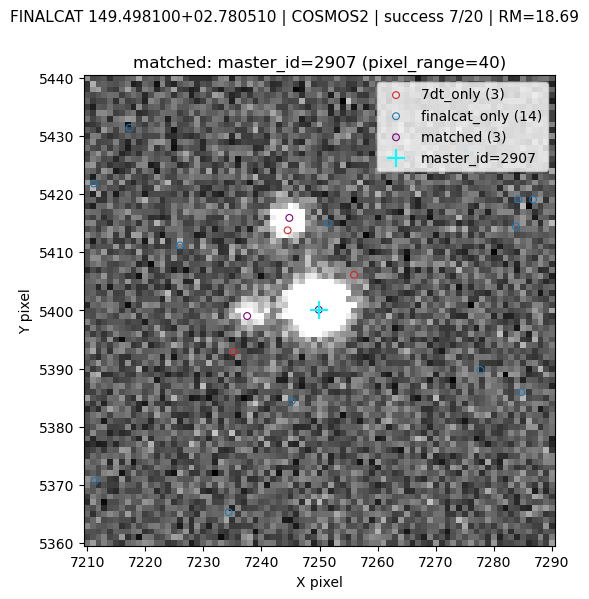

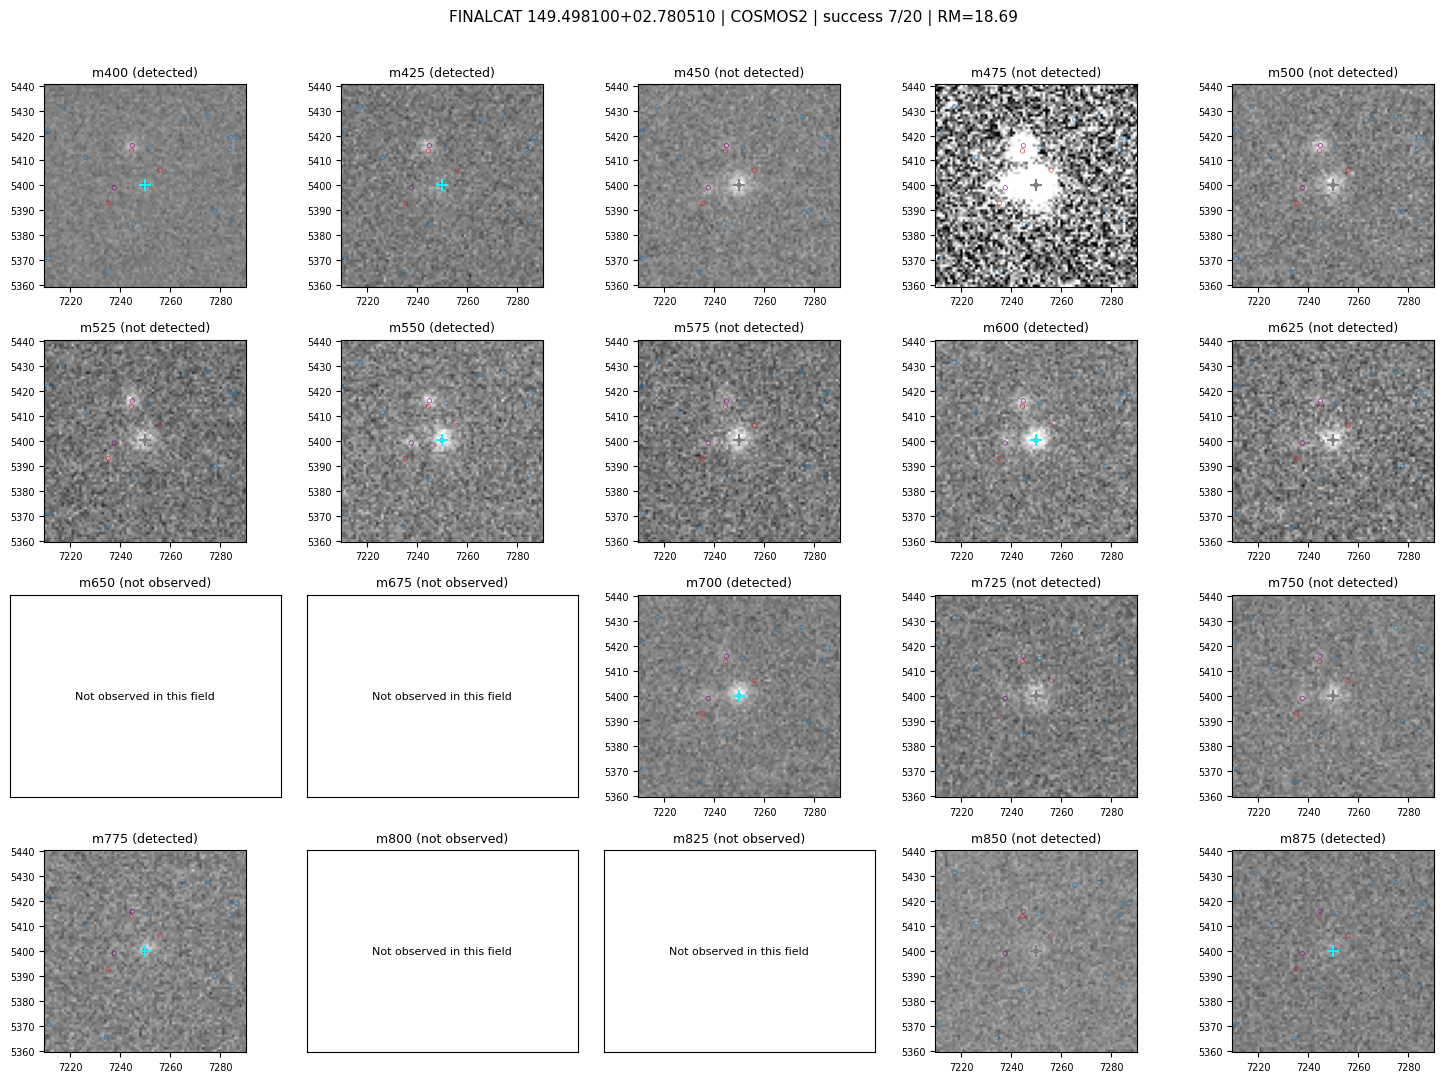

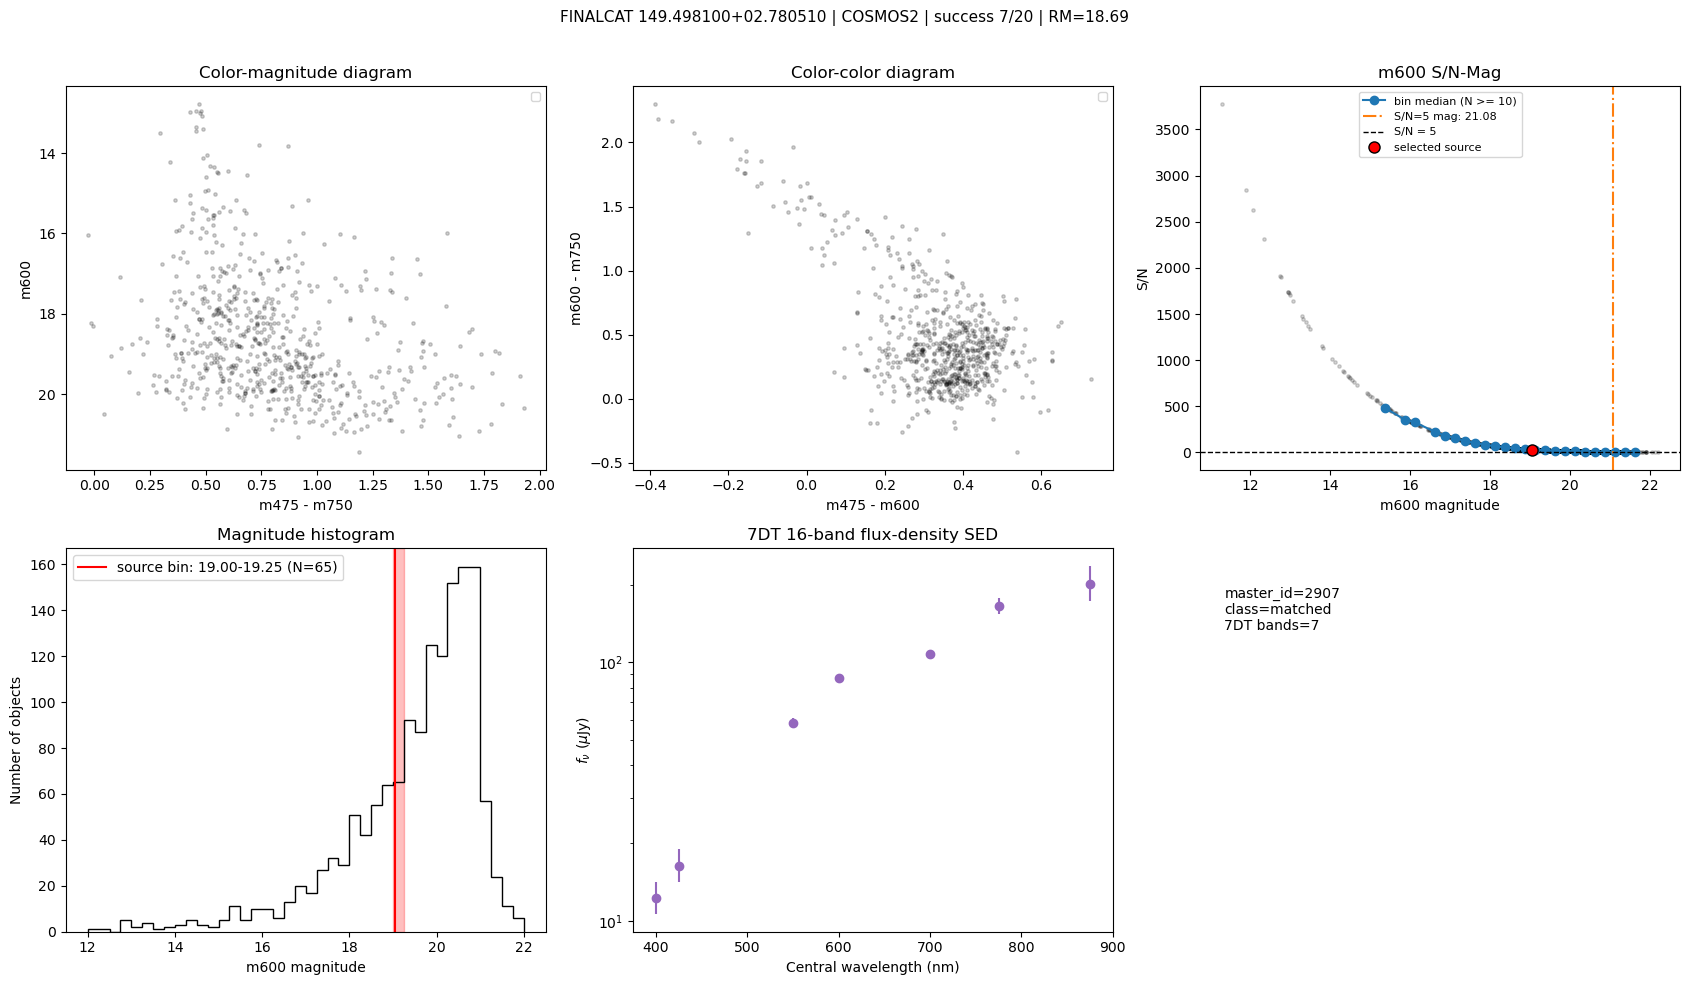


FINALCAT 150.011249+02.156633 | COSMOS1, master_id=24396 | successful=2/20; observed=20/20; RM=21.23


band,observed,successful,mag,mag_err,status
str4,bool,bool,float64,float64,str12
m400,True,False,nan,nan,not detected
m425,True,False,nan,nan,not detected
m450,True,False,nan,nan,not detected
m475,True,False,nan,nan,not detected
m500,True,False,nan,nan,not detected
m525,True,False,nan,nan,not detected
m550,True,False,nan,nan,not detected
m575,True,False,nan,nan,not detected
m600,True,False,nan,nan,not detected



Source information: master_id=24396
Image/catalog position
master_id master_class     master_ra         master_dec         master_x           master_y     n_7dt_bands has_finalcat has_sdss
--------- ------------ ----------------- ----------------- ------------------ ----------------- ----------- ------------ --------
    24396      matched 150.0112760044906 2.156560761462017 3595.4241769265454 4873.123161393161           2         True     True

Detection-image cutout



7DT 20-band cutouts



7DT photometry and morphology
band wavelength_nm detected source_id        mag               mag_err              snr           ellipticity      flux_radius_pix    derived_fwhm_pix  derived_fwhm_arcsec   band_fwhm_pix     band_fwhm_arcsec     extendicity    
---- ------------- -------- --------- ------------------ ------------------- ----------------- ------------------ ------------------ ------------------ ------------------- ------------------ ------------------ ------------------
m400           400    False        -1                nan                 nan               nan                nan                nan                nan                 nan  5.251121520996094  2.651816368103447                nan
m425           425    False        -1                nan                 nan               nan                nan                nan                nan                 nan  5.827403545379639 2.9428387904171833                nan
m450           450    False        -1                

/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:224: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].set(xlabel='m475 - m750', ylabel='m600', title='Color-magnitude diagram'); axes[0, 0].invert_yaxis(); axes[0, 0].legend(fontsize=8)
/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:229: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 1].set(xlabel='m475 - m600', ylabel='m600 - m750', title='Color-color diagram'); axes[0, 1].legend(fontsize=8)


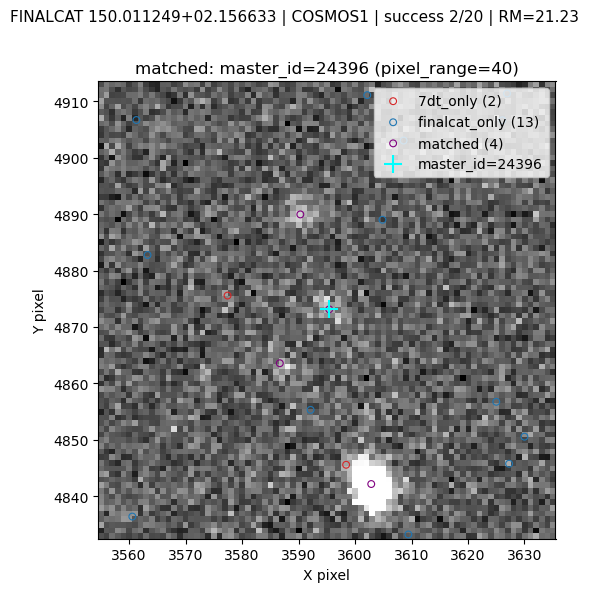

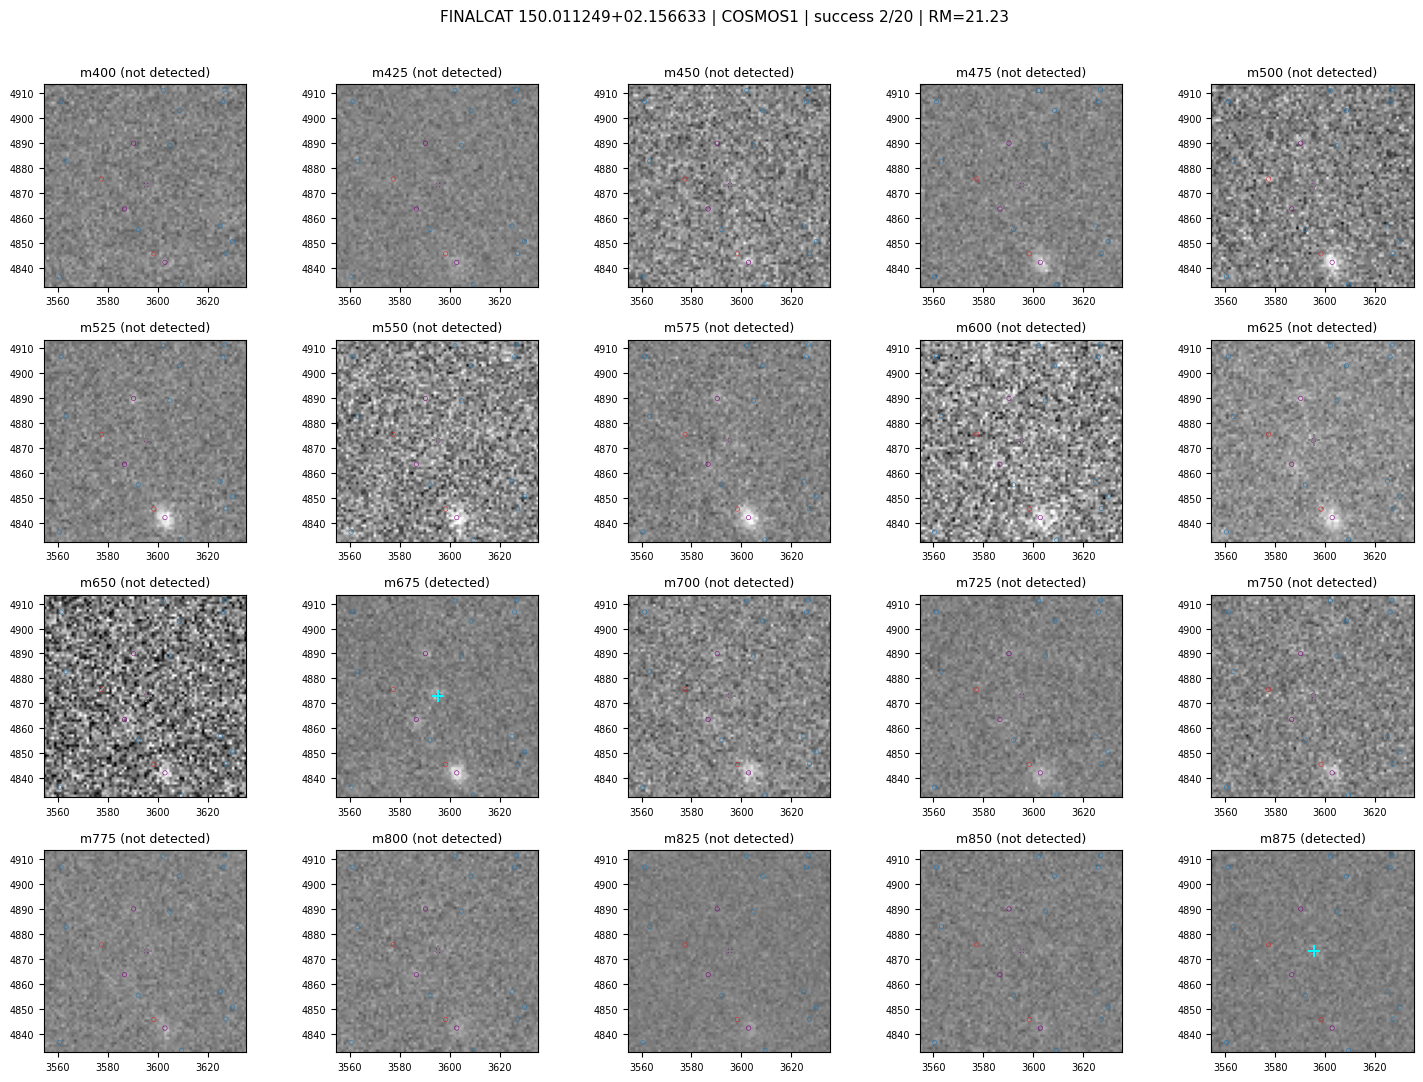

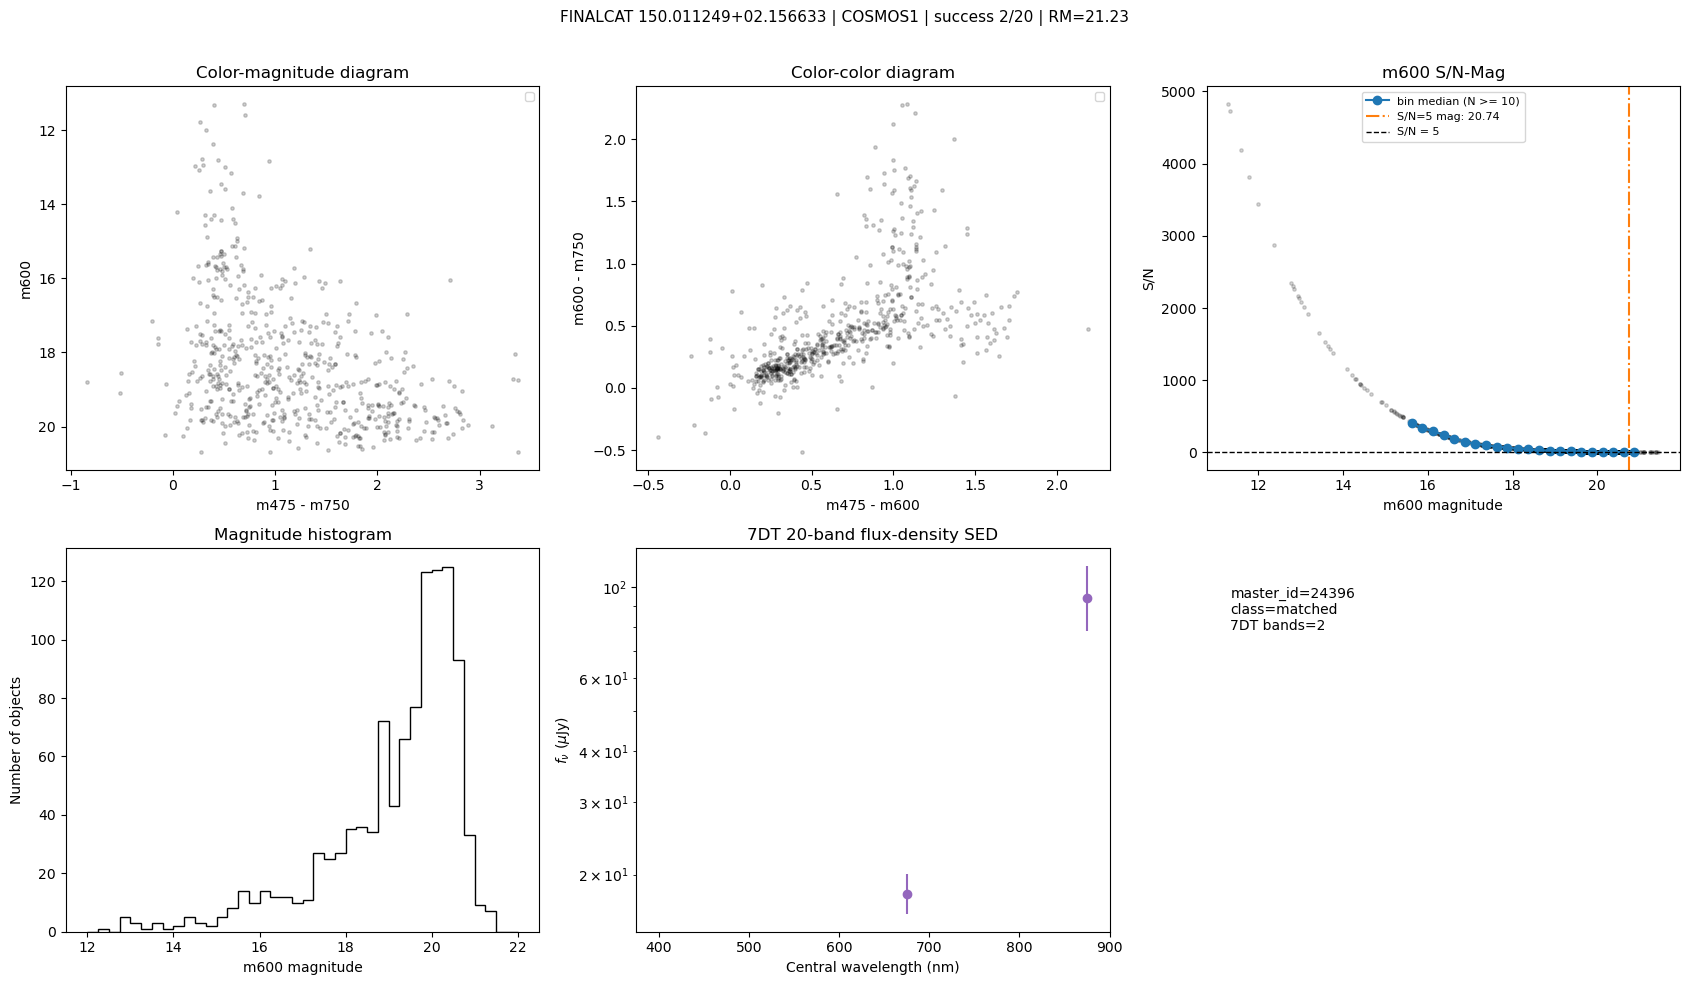


FINALCAT 150.413888+02.177963 | COSMOS2, master_id=408 | successful=1/20; observed=16/20; RM=23.99


band,observed,successful,mag,mag_err,status
str4,bool,bool,float64,float64,str12
m400,True,True,21.830524444580078,0.28885069489479065,success
m425,True,False,nan,nan,not detected
m450,True,False,nan,nan,not detected
m475,True,False,nan,nan,not detected
m500,True,False,nan,nan,not detected
m525,True,False,nan,nan,not detected
m550,True,False,nan,nan,not detected
m575,True,False,nan,nan,not detected
m600,True,False,nan,nan,not detected



Source information: master_id=408
Image/catalog position
master_id master_class     master_ra          master_dec    master_x      master_y     n_7dt_bands has_finalcat has_sdss
--------- ------------ ------------------ ----------------- -------- ----------------- ----------- ------------ --------
      408      matched 150.41401169948202 2.177883375855801 726.3125 1105.089599609375           1         True    False

Detection-image cutout



7DT 16-band cutouts

7DT photometry and morphology
band wavelength_nm detected source_id        mag               mag_err              snr            ellipticity      flux_radius_pix  derived_fwhm_pix derived_fwhm_arcsec   band_fwhm_pix     band_fwhm_arcsec     extendicity    
---- ------------- -------- --------- ------------------ ------------------- ------------------ ------------------ ----------------- ---------------- ------------------- ------------------ ------------------ ------------------
m400           400     True      6250 21.830524444580078 0.28885069489479065 3.7586892439204598 0.4997924566268921 1.455222725868225 2.91044545173645    1.46977495312714 6.0639355182647705 3.0622874367241937 0.4799598285585482
m425           425    False        -1                nan                 nan                nan                nan               nan              nan                 nan  7.242830753326416  3.657629530430419                nan
m450           450    False        -1   


Informative plots


/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:224: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].set(xlabel='m475 - m750', ylabel='m600', title='Color-magnitude diagram'); axes[0, 0].invert_yaxis(); axes[0, 0].legend(fontsize=8)
/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:229: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 1].set(xlabel='m475 - m600', ylabel='m600 - m750', title='Color-color diagram'); axes[0, 1].legend(fontsize=8)


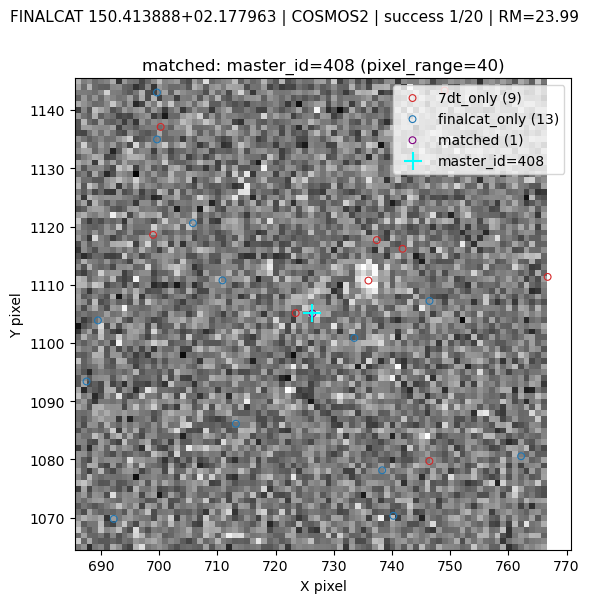

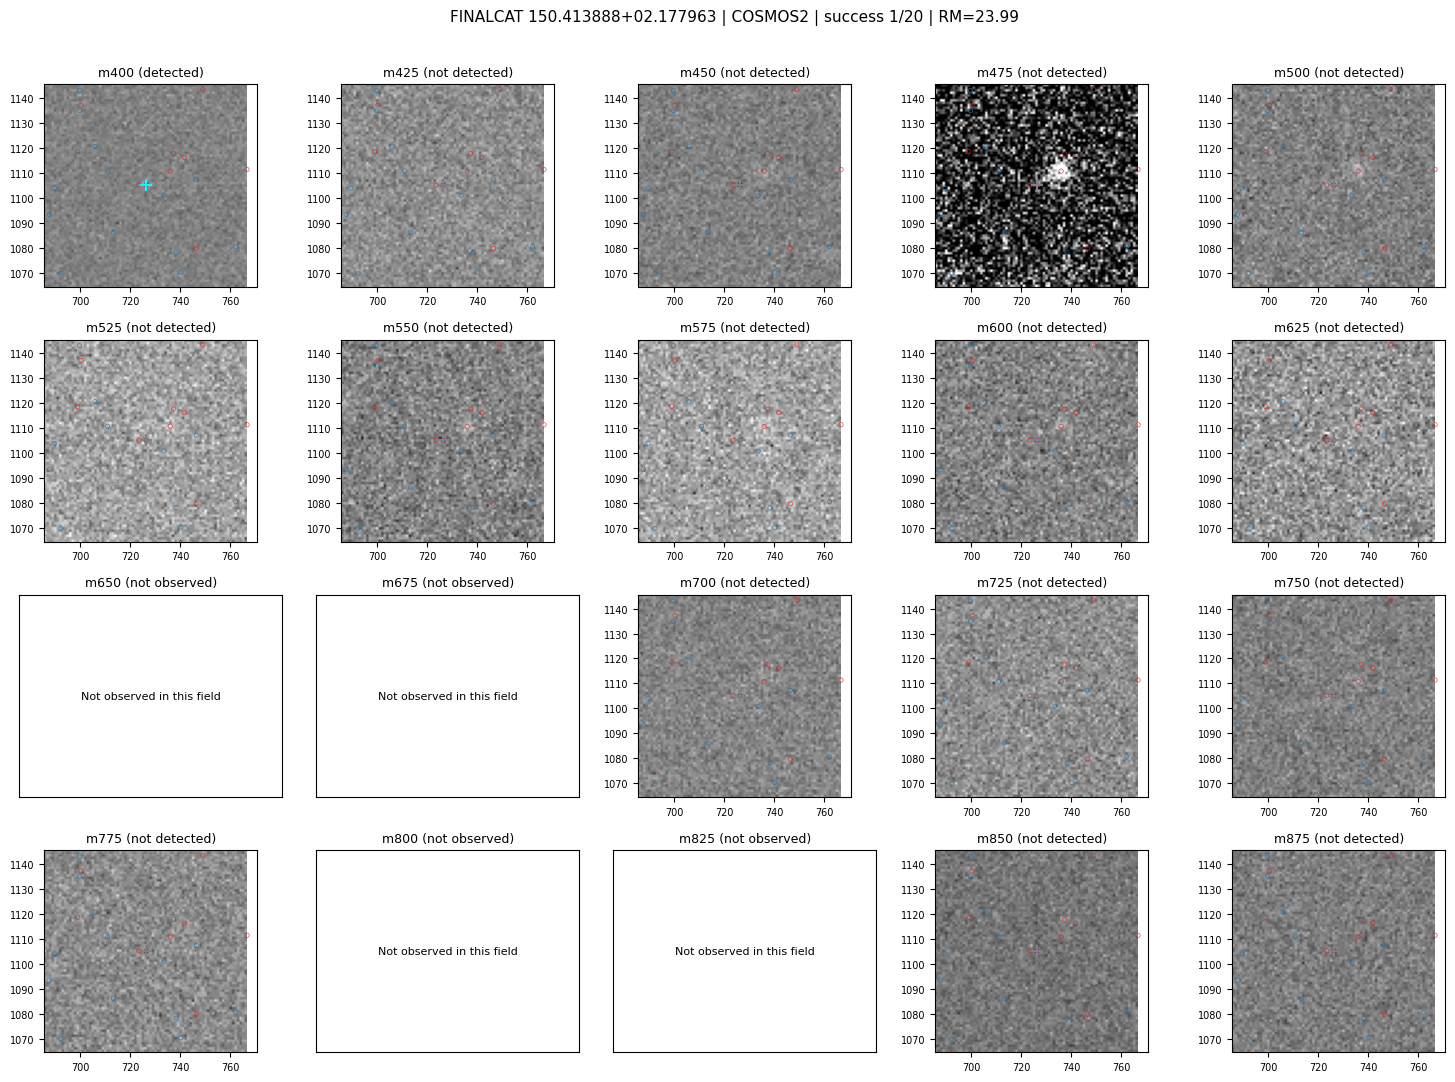

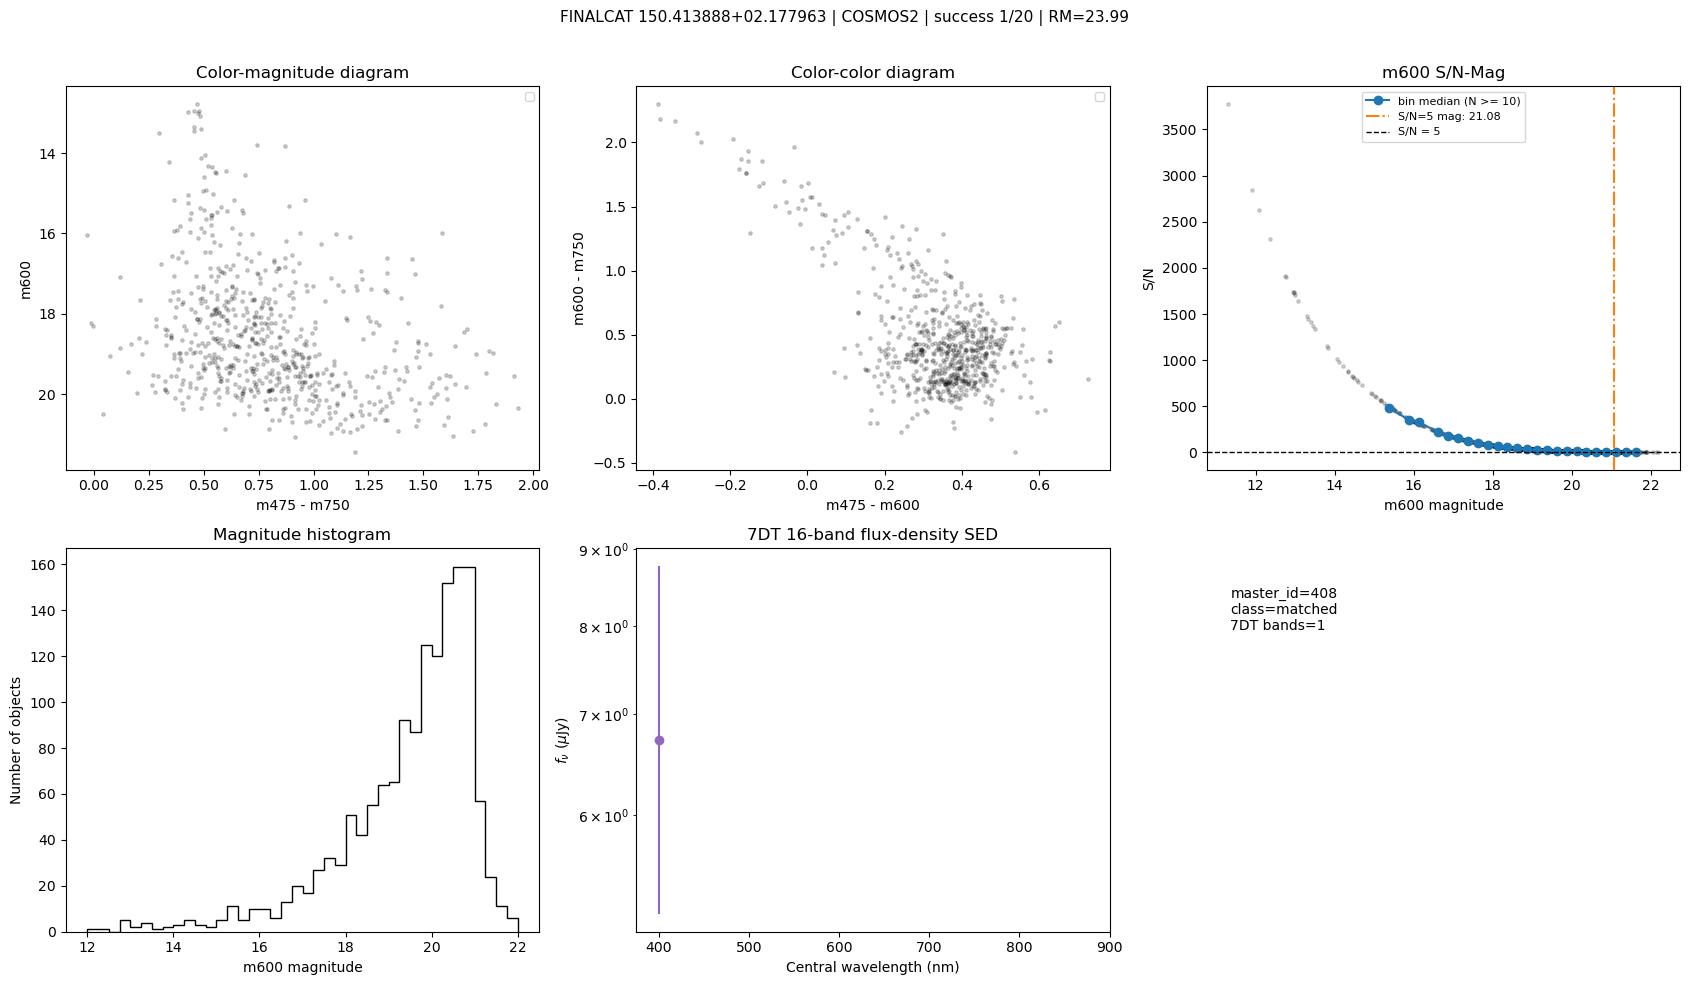


FINALCAT 150.490730+01.788927 | COSMOS3, master_id=629 | successful=15/20; observed=18/20; RM=unavailable


band,observed,successful,mag,mag_err,status
str4,bool,bool,float64,float64,str12
m400,True,True,17.684404373168945,0.04541107639670372,success
m425,True,True,17.591297149658203,0.023481838405132294,success
m450,True,False,nan,nan,not detected
m475,True,True,17.079160690307617,0.003452735021710396,success
m500,True,True,17.005355834960938,0.015987813472747803,success
m525,True,True,16.992504119873047,0.010399634018540382,success
m550,True,True,16.874073028564453,0.02075417898595333,success
m575,True,True,16.738399505615234,0.010389653034508228,success
m600,True,True,16.702892303466797,0.022466769441962242,success



Source information: master_id=629
Image/catalog position
master_id master_class     master_ra          master_dec          master_x          master_y     n_7dt_bands has_finalcat has_sdss
--------- ------------ ------------------ ------------------ ----------------- ----------------- ----------- ------------ --------
      629      matched 150.49074898311204 1.7889133985625512 4453.888758459356 2252.172830903084          15         True     True

Detection-image cutout



7DT 18-band cutouts

7DT photometry and morphology
band wavelength_nm detected source_id        mag               mag_err               snr             ellipticity       flux_radius_pix    derived_fwhm_pix  derived_fwhm_arcsec   band_fwhm_pix     band_fwhm_arcsec     extendicity    
---- ------------- -------- --------- ------------------ -------------------- ------------------ -------------------- ------------------ ------------------ ------------------- ------------------ ------------------ ------------------
m400           400     True      4639 17.684404373168945  0.04541107639670372  23.90826393357213  0.12584656476974487 3.3965647220611572 6.7931294441223145   3.430530369282312  6.070355176925659  3.065529364347943 1.1190662236608544
m425           425     True      5802 17.591297149658203 0.023481838405132294 46.235732537990074  0.07104772329330444 3.6232550144195557  7.246510028839111  3.6594875645643303  7.064942836761475 3.5677961325651095 1.0256997397251222
m450           4


Informative plots


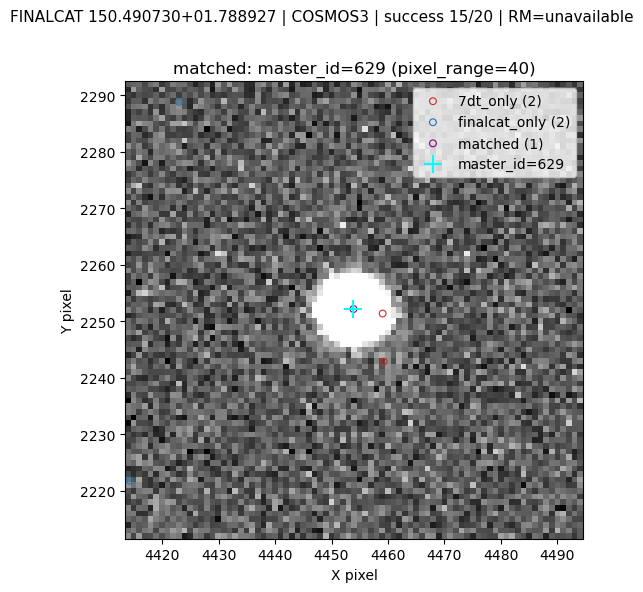

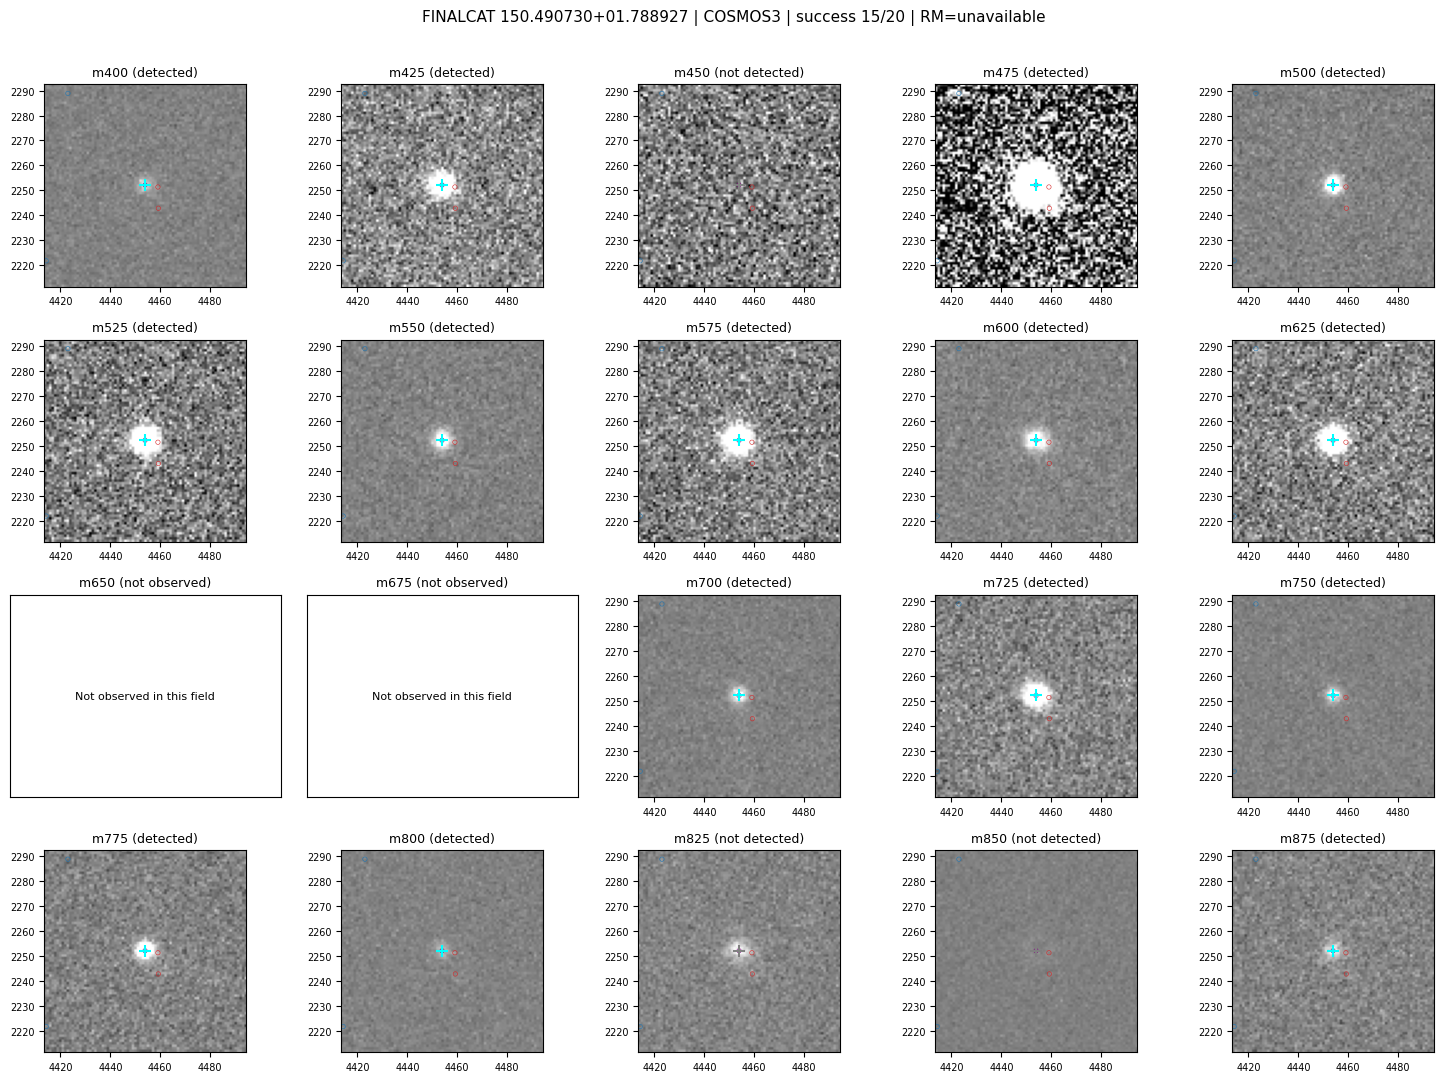

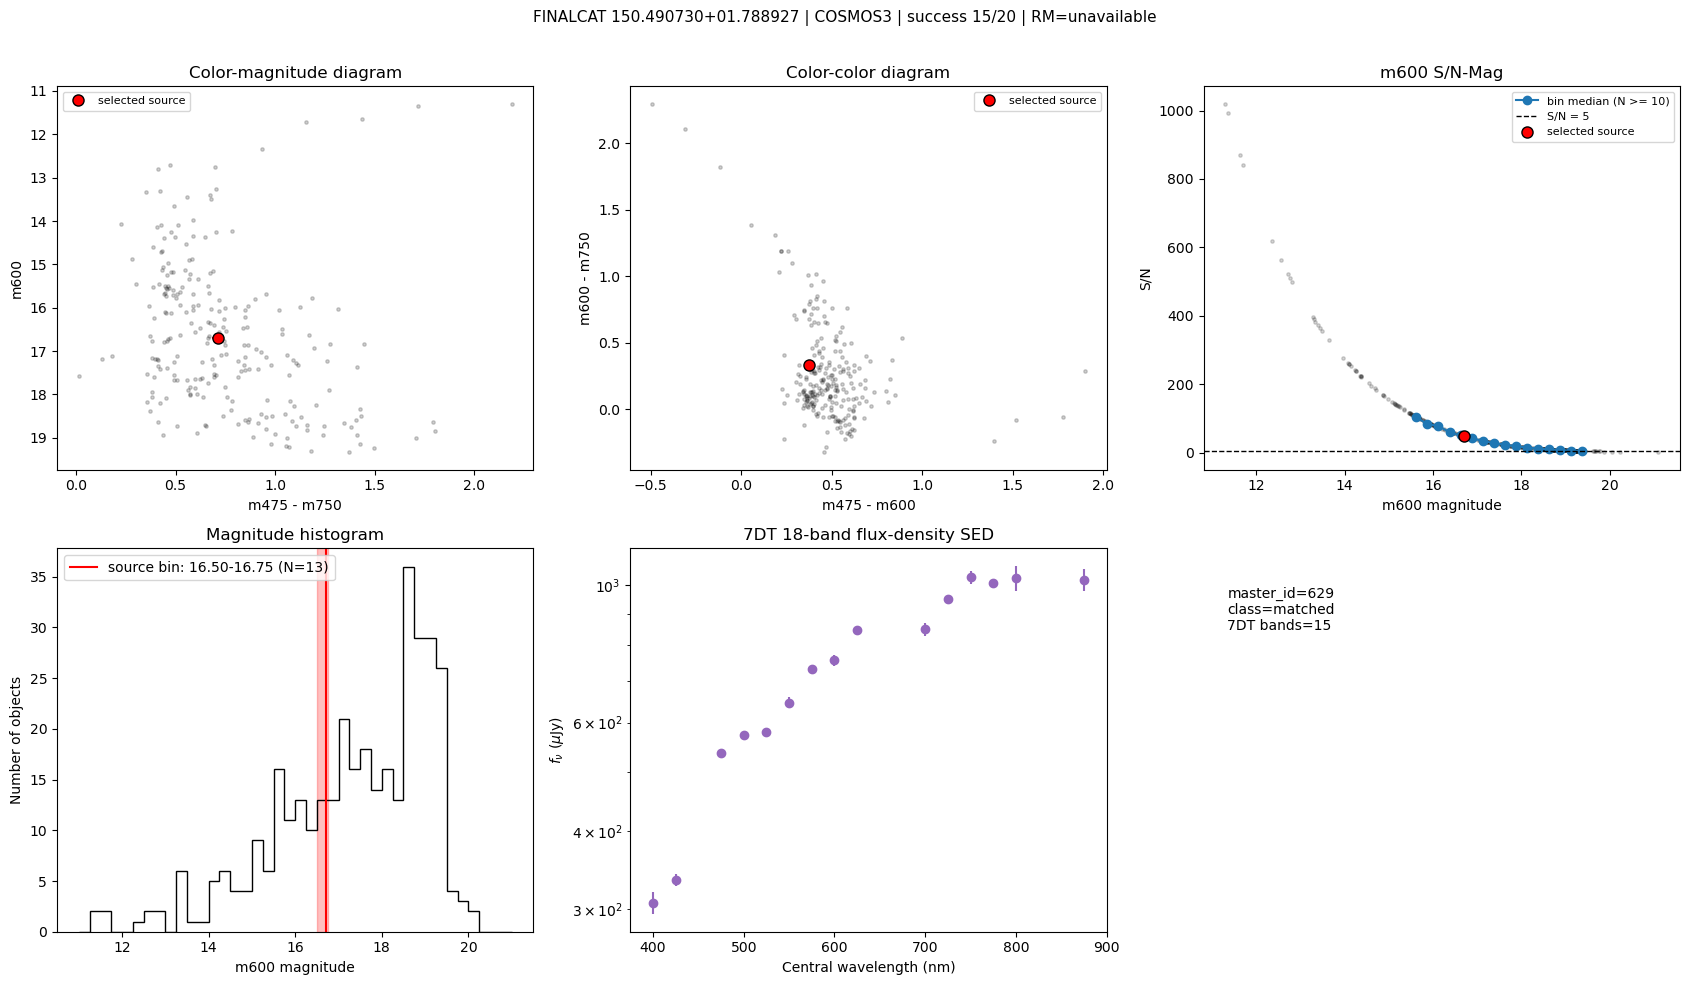


FINALCAT 150.234047+01.670142 | COSMOS1, master_id=3711 | successful=8/20; observed=20/20; RM=19.78


band,observed,successful,mag,mag_err,status
str4,bool,bool,float64,float64,str12
m400,True,False,nan,nan,not detected
m425,True,True,21.37611961364746,0.12273610383272171,success
m450,True,False,nan,nan,not detected
m475,True,True,21.12291145324707,0.10769260674715042,success
m500,True,True,20.922725677490234,0.12437988072633743,success
m525,True,False,nan,nan,not detected
m550,True,True,20.349966049194336,0.13293296098709106,success
m575,True,True,20.28213882446289,0.06887051463127136,success
m600,True,False,nan,nan,not detected



Source information: master_id=3711
Image/catalog position
master_id master_class     master_ra         master_dec          master_x           master_y      n_7dt_bands has_finalcat has_sdss
--------- ------------ ----------------- ------------------ ------------------ ------------------ ----------- ------------ --------
     3711      matched 150.2340451468378 1.6701077666035027 2007.5351964949255 1405.5542098290853           8         True     True

Detection-image cutout



7DT 20-band cutouts

7DT photometry and morphology
band wavelength_nm detected source_id        mag               mag_err              snr             ellipticity       flux_radius_pix    derived_fwhm_pix derived_fwhm_arcsec   band_fwhm_pix     band_fwhm_arcsec     extendicity    
---- ------------- -------- --------- ------------------ ------------------- ------------------ -------------------- ------------------ ----------------- ------------------- ------------------ ------------------ ------------------
m400           400    False        -1                nan                 nan                nan                  nan                nan               nan                 nan  5.251121520996094  2.651816368103447                nan
m425           425     True      5606  21.37611961364746 0.12273610383272171  8.845807925267954  0.27651160955429077    4.0528883934021   8.1057767868042   4.093417277336768  5.827403545379639 2.9428387904171833 1.3909757104827603
m450           450    Fa

/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:224: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].set(xlabel='m475 - m750', ylabel='m600', title='Color-magnitude diagram'); axes[0, 0].invert_yaxis(); axes[0, 0].legend(fontsize=8)
/var/folders/fd/sr9dc9td6rnc8xmntjxzpjh80000gn/T/ipykernel_84589/490108589.py:229: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 1].set(xlabel='m475 - m600', ylabel='m600 - m750', title='Color-color diagram'); axes[0, 1].legend(fontsize=8)


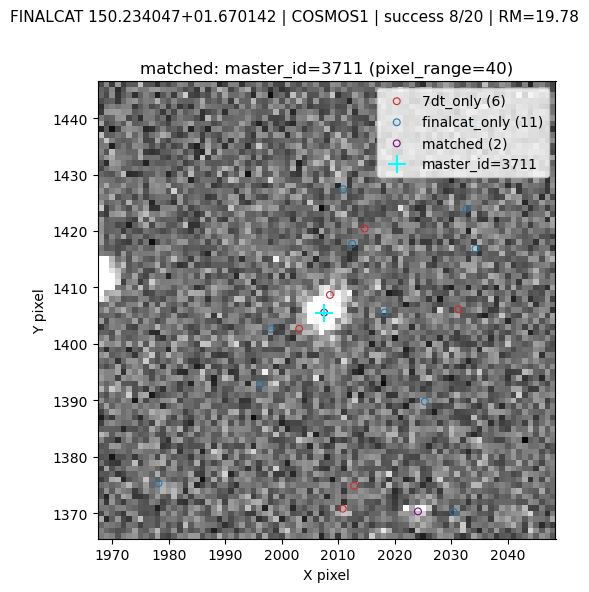

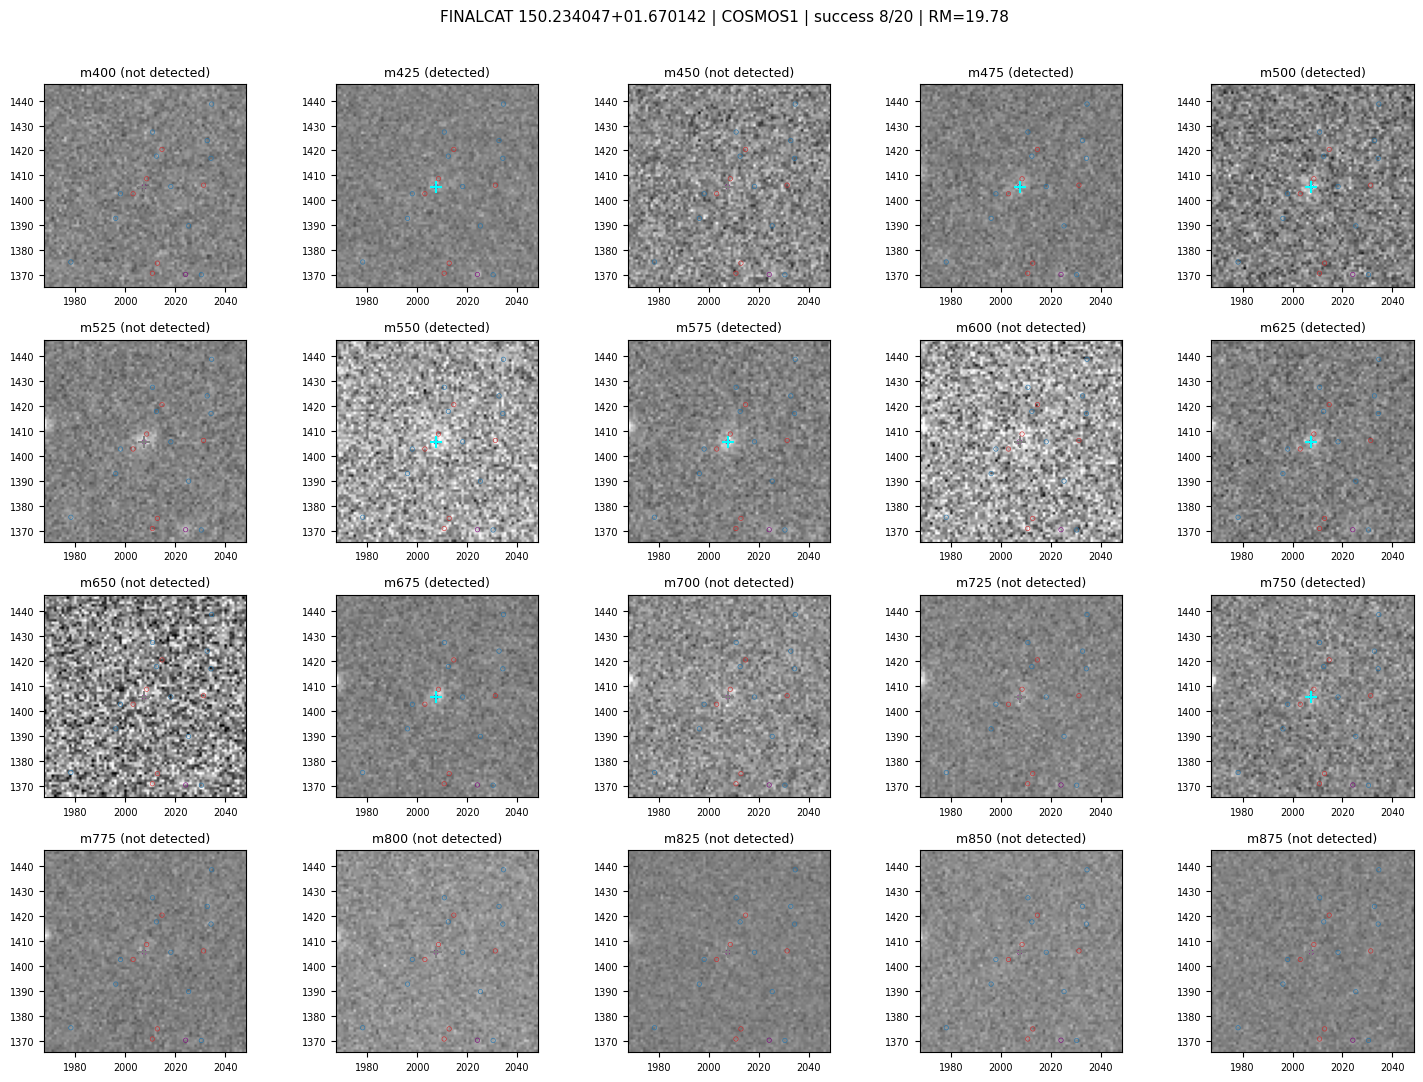

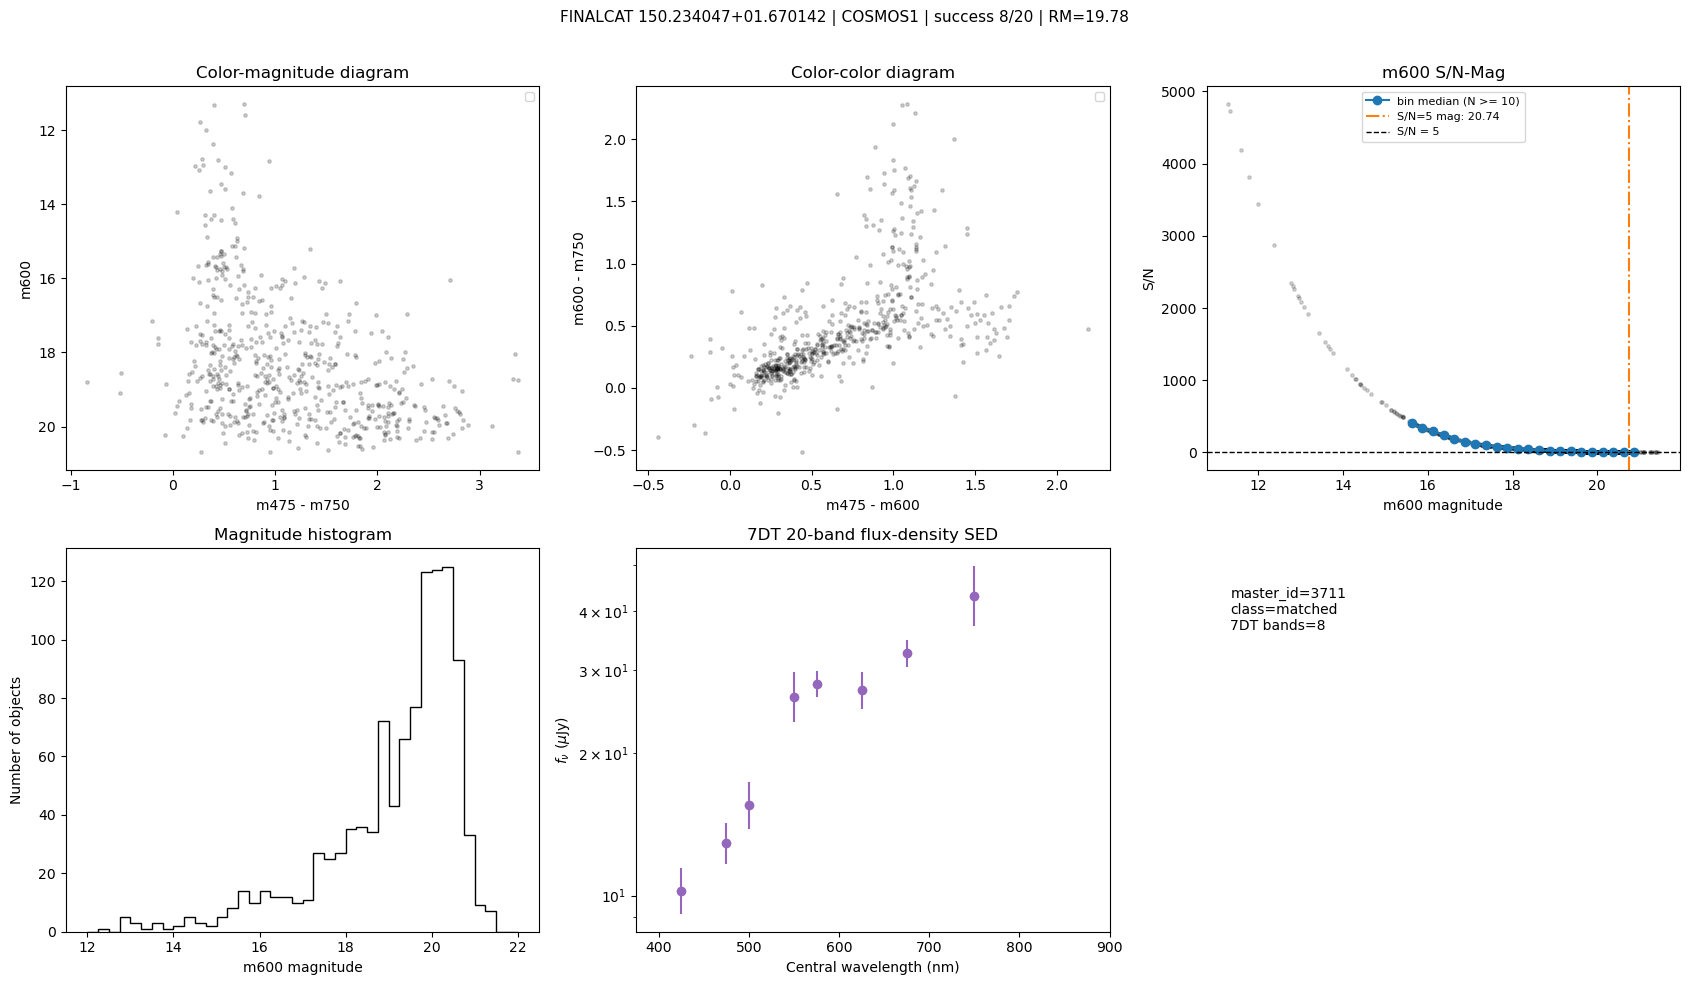

Saved 5 examples (3 figures each), tables, and histograms to /Users/mac_seo/Research_local/7DTonCOSMOS/output/singlephot/analysis/numofmatchedbands


In [6]:
rng = np.random.default_rng(RANDOM_SEED)
example_pool = np.flatnonzero(not_all_mask)
if len(example_pool) < N_EXAMPLES:
    raise RuntimeError(f'Only {len(example_pool)} not-all-band sources; need {N_EXAMPLES}')
example_indices = rng.choice(example_pool, size=N_EXAMPLES, replace=False)
examples = combined[example_indices]
examples[['finalcat_idx', 'ID', 'RM', 'selected_COSMOS', 'selected_master_id', 'n_success_bands', 'n_available_bands']].write(
    ANALYSIS_DIR / 'random_example_selection.csv', format='ascii.csv', overwrite=True)
display(examples[['ID', 'RM', 'selected_COSMOS', 'selected_master_id', 'n_success_bands', 'n_available_bands']])

# Load only the field currently inspected; memory-mapped images are released on switching.
manifest_rows = []
loaded_field = None
for row in examples:
    COSMOS = int(row['selected_COSMOS'])
    if loaded_field != COSMOS:
        if loaded_field is not None:
            del band_images, detection_image
        PRODUCT_DIR = PROJECT_ROOT / f'output/COSMOS{COSMOS}/singlephot'
        MATCH_DIR = PRODUCT_DIR / 'diagnostics'
        ACTIVE_BANDS = active_by_field[COSMOS]
        N_ACTIVE_BANDS = len(ACTIVE_BANDS)
        REFERENCE_BAND = min(ACTIVE_BANDS, key=lambda b: abs(int(b[1:]) - 600))
        master = masters[COSMOS]
        image_candidates = [DATA_ROOT / f'COSMOS{COSMOS}/COSMOS{COSMOS}_detectionimage.fits',
                            PROJECT_ROOT / f'output/COSMOS{COSMOS}/COSMOS{COSMOS}_detectionimage.fits']
        detection_path = next((p for p in image_candidates if p.exists()), get_image_path(COSMOS, REFERENCE_BAND))
        detection_image = fits.getdata(detection_path, memmap=True)
        band_images = {b: fits.getdata(get_image_path(COSMOS, b), memmap=True) for b in ACTIVE_BANDS}
        loaded_field = COSMOS
    source_id = int(row['selected_master_id'])
    source_idx = int(row['selected_master_row'])
    assert int(master['master_id'][source_idx]) == source_id
    assert int(master['finalcat_idx'][source_idx]) == int(row['finalcat_idx'])
    rm_label = f"{float(row['RM']):.2f}" if np.isfinite(row['RM']) and 0 < row['RM'] < 50 else 'unavailable'
    print(f"\nFINALCAT {row['ID']} | COSMOS{COSMOS}, master_id={source_id} | successful={row['n_success_bands']}/20; observed={N_ACTIVE_BANDS}/20; RM={rm_label}")
    status = Table()
    status['band'] = BANDS_7DT
    status['observed'] = [b in ACTIVE_BANDS for b in BANDS_7DT]
    status['successful'] = [bool(row[f'{b}_success']) for b in BANDS_7DT]
    status['mag'] = [float(row[f'{b}_mag']) for b in BANDS_7DT]
    status['mag_err'] = [float(row[f'{b}_mag_err']) for b in BANDS_7DT]
    status['status'] = ['success' if row[f'{b}_success'] else ('not observed' if b not in ACTIVE_BANDS else ('not detected' if row[f'{b}_source_id'] < 0 else 'invalid photometry')) for b in BANDS_7DT]
    display(status)
    result = plot_SourceInfoFromCatalog(master, image=detection_image, pixel_range=PIXEL_RANGE,
        source_id=source_id, info_catalog=master,
        population_catalog=master[np.asarray(master['master_class']).astype(str) == 'matched'],
        diagnostic_band=REFERENCE_BAND, show=False)
    prefix = f"finalcat{int(row['finalcat_idx'])}_cosmos{COSMOS}_master{source_id}"
    label = f"FINALCAT {row['ID']} | COSMOS{COSMOS} | success {row['n_success_bands']}/20 | RM={rm_label}"
    paths = {}
    for kind, figure in [('detection', result['image'][0]), ('bands', result['cutout_figure']), ('diagnostics', result['diagnostic_figure'])]:
        figure.suptitle(label, fontsize=11)
        figure.tight_layout(rect=(0, 0, 1, 0.97))
        path = EXAMPLE_DIR / f'{prefix}_{kind}.png'
        figure.savefig(path, dpi=120, bbox_inches='tight')
        paths[kind] = str(path.relative_to(PROJECT_ROOT))
        display(figure)
        plt.close(figure)
    status.write(EXAMPLE_DIR / f'{prefix}_band_status.csv', format='ascii.csv', overwrite=True)
    manifest_rows.append((int(row['finalcat_idx']), str(row['ID']), COSMOS, source_id, int(row['n_success_bands']), *paths.values()))
manifest = Table(rows=manifest_rows, names=['finalcat_idx', 'ID', 'COSMOS', 'master_id', 'n_success_bands', 'detection_png', 'bands_png', 'diagnostics_png'])
manifest.write(ANALYSIS_DIR / 'example_manifest.csv', format='ascii.csv', overwrite=True)
assert len(manifest) == N_EXAMPLES
print(f'Saved {len(manifest)} examples (3 figures each), tables, and histograms to {ANALYSIS_DIR}')